# Tarea 04 - NLTK: Procesamiento de lenguaje natural sobre reseñas de restaurantes

Aplicación de técnicas de procesamiento de lenguaje natural con la librería **NLTK** sobre las reseñas de restaurantes obtenidas por *web scraping* en la semana 03 (notebook `02_CityPeru_Scraping.ipynb`). La data se extrajo con Selenium del portal [cityperu.com](https://cityperu.com) y contiene 1,012 reseñas de 13 restaurantes de Lima.

**Objetivo:** responder preguntas de negocio sobre los restaurantes (qué valoran los clientes, qué platos mencionan, qué aspectos aparecen en las reseñas con menor calificación) a partir del texto de las reseñas.

Todas las técnicas se aplican sobre las reseñas extraídas. El corpus `cess_esp` de NLTK se usa para entrenar el etiquetador (Técnica 9) y, junto con WordNet, como diccionario auxiliar (Técnica 11); WordNet es además la base de la Técnica 12.

| N | Técnica | Funciones NLTK | Caso de uso sobre las reseñas |
|---|---------|----------------|-------------------------------|
| 1 | Segmentación de oraciones | `sent_tokenize` | Medir el nivel de detalle de cada reseña según su calificación |
| 2 | Tokenización de palabras | `word_tokenize`, `RegexpTokenizer`, `TweetTokenizer` | Separar el texto en palabras y comparar tokenizadores con texto informal |
| 3 | Normalización y stopwords | `stopwords.words('spanish')` | Quitar palabras sin contenido y reducir el vocabulario |
| 4 | Stemming | `SnowballStemmer('spanish')` | Agrupar variantes de una misma palabra (recomiendo, recomendable, ...) |
| 5 | Distribución de frecuencias | `FreqDist` | Identificar los temas más mencionados por los clientes |
| 6 | Frecuencia condicional | `ConditionalFreqDist` | Comparar el vocabulario de reseñas de 3, 4 y 5 estrellas y por restaurante |
| 7 | N-gramas y colocaciones | `ngrams`, `BigramCollocationFinder`, `TrigramCollocationFinder` | Detectar los platos más mencionados (lomo saltado, caldo de gallina, ...) |
| 8 | Concordancia y contexto | `Text.concordance_list`, `similar`, `common_contexts`, `dispersion_plot` | Leer en contexto las menciones a la cola, el precio y la atención |
| 9 | Etiquetado gramatical (POS) | `UnigramTagger`, `BigramTagger`, `RegexpTagger` | Obtener los sustantivos y adjetivos más usados |
| 10 | Chunking | `RegexpParser` | Extraer pares aspecto-opinión ("comida rica", "atención rápida") |
| 11 | Distancia de edición | `edit_distance` | Detectar y corregir palabras mal escritas o sin tilde |
| 12 | Similitud semántica (WordNet) | `wordnet.synsets(lang='spa')`, `wup_similarity` | Clasificar sustantivos en aspectos (comida, servicio, ambiente, precio, espera) |
| 13 | TF-IDF | `TextCollection.tf_idf` | Encontrar los términos que distinguen a cada restaurante |
| 14 | Clasificación de sentimiento | `NaiveBayesClassifier`, `ConfusionMatrix` | Predecir si una reseña es de 5 estrellas a partir de su texto |

## 1. Configuración del entorno

Importación de librerías, descarga de los recursos de NLTK y configuración de las gráficas. Se fija la semilla aleatoria para que los resultados sean reproducibles.

In [1]:
import random
import textwrap
import unicodedata
import warnings
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud

import nltk
from nltk.tokenize import sent_tokenize, word_tokenize, RegexpTokenizer, TweetTokenizer
from nltk.corpus import stopwords, cess_esp, wordnet as wn
from nltk.stem import SnowballStemmer
from nltk.probability import FreqDist, ConditionalFreqDist
from nltk.util import ngrams
from nltk.collocations import (BigramCollocationFinder, TrigramCollocationFinder,
                               BigramAssocMeasures, TrigramAssocMeasures)
from nltk.text import Text, TextCollection
from nltk.tag import DefaultTagger, RegexpTagger, UnigramTagger, BigramTagger
from nltk.chunk import RegexpParser
from nltk.metrics.distance import edit_distance
from nltk.classify import NaiveBayesClassifier
from nltk.classify import accuracy as nltk_accuracy
from nltk.metrics import ConfusionMatrix, precision, recall, f_measure

# nltk.draw solo avisa que no hay Tkinter; dispersion_plot usa matplotlib
warnings.filterwarnings("ignore", message="nltk.draw package not loaded")
from nltk.draw.dispersion import dispersion_plot

# Recursos de NLTK (si ya están descargados no se vuelven a bajar)
for recurso in ["punkt", "punkt_tab", "stopwords", "cess_esp", "wordnet", "omw-1.4"]:
    nltk.download(recurso, quiet=True)

# Reproducibilidad y estilo
SEMILLA = 42
random.seed(SEMILLA)
np.random.seed(SEMILLA)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.max_colwidth", 80)
pd.set_option("display.width", 100)


def sin_simbolos(texto, reemplazo=""):
    # Quita emojis y símbolos gráficos (fuera del plano básico o categoría Unicode "So")
    return "".join(reemplazo if (ord(c) > 0xFFFF or unicodedata.category(c) == "So") else c
                   for c in texto if c not in "\ufe0f\u200d")


print("NLTK", nltk.__version__)

NLTK 3.10.3


## 2. Data

Carga del CSV generado en la semana 03. Cada fila es una reseña con su calificación, el texto, el usuario, la página del listado y los datos del restaurante.

In [2]:
df = pd.read_csv("02_reseñas_restaurantes.csv", encoding="utf-8-sig")
print(f"Registros: {df.shape[0]} | Columnas: {df.shape[1]}")
df.info()

Registros: 1012 | Columnas: 8
<class 'pandas.DataFrame'>
RangeIndex: 1012 entries, 0 to 1011
Data columns (total 8 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   calificacion_resena    1012 non-null   float64
 1   texto                  1012 non-null   str    
 2   usuario                1012 non-null   str    
 3   pagina                 1012 non-null   int64  
 4   nombre_restaurante     1012 non-null   str    
 5   enlace                 1012 non-null   str    
 6   calificacion_general   1012 non-null   float64
 7   direccion_restaurante  1012 non-null   str    
dtypes: float64(2), int64(1), str(5)
memory usage: 63.4 KB


In [3]:
print("Nulos en total:", df.isnull().sum().sum())
print(f"Reseñas con texto duplicado: {df['texto'].duplicated().sum()}")
print("\nEjemplo de nombre_restaurante:", df.loc[0, "nombre_restaurante"])
print("Ejemplo de direccion_restaurante:", df.loc[0, "direccion_restaurante"])

Nulos en total: 0
Reseñas con texto duplicado: 0

Ejemplo de nombre_restaurante: Opiniones de Siete Sopas Lince. (Restaurante) en Lince (Lima).
Ejemplo de direccion_restaurante: 804onal GaiAv. Arequipa 2394, LimaD


La columna `nombre_restaurante` contiene una frase fija (*"Opiniones de X. (Restaurante) en Distrito (Lima)."*), por lo que se extraen el nombre y el distrito con una expresión regular. La columna `direccion_restaurante` quedó con texto mezclado durante el scraping (por ejemplo `804onal GaiAv. Arequipa...`) y no se usa en el análisis.

In [4]:
patron = (r"Opiniones de (?P<restaurante>.+?)\. \(Restaurante\) "
          r"en (?P<distrito>.+?) \(Lima\)")
df[["restaurante", "distrito"]] = df["nombre_restaurante"].str.extract(patron)
df["calificacion"] = df["calificacion_resena"].astype(int)
df = df.drop(columns=["nombre_restaurante", "direccion_restaurante"])

print("Filas sin nombre extraído:", df["restaurante"].isna().sum())
df[["calificacion", "usuario", "restaurante", "distrito"]].head(3)

Filas sin nombre extraído: 0


,calificacion,usuario,restaurante,distrito
0,5,K. E.,Siete Sopas Lince,Lince
1,4,B. S.,Siete Sopas Lince,Lince
2,5,J. V.,Siete Sopas Lince,Lince


In [5]:
resumen = (df.groupby(["restaurante", "distrito"])
             .agg(resenas=("calificacion", "size"),
                  calif_media=("calificacion", "mean"),
                  pct_5_estrellas=("calificacion", lambda s: (s == 5).mean() * 100))
             .round(2)
             .sort_values("resenas", ascending=False))
resumen

,,resenas,calif_media,pct_5_estrellas
restaurante,distrito,,,
Siete Sopas Lince,Lince,103,4.53,61.17
Restaurante La Rosa Náutica,Miraflores,96,4.68,75.00
Panchita - Miraflores,Miraflores,95,4.68,74.74
La Mar Restaurante,Miraflores,93,4.74,81.72
Cala Restaurante & Lounge,Barranco,93,4.75,78.49
El Rancho de Robertin,Huaral,90,4.46,60.00
Restaurant Huaca Pucllana,Miraflores,90,4.70,74.44
Punto Azul,Miraflores,89,4.58,66.29
Restaurante Javier,Barranco,88,4.64,69.32


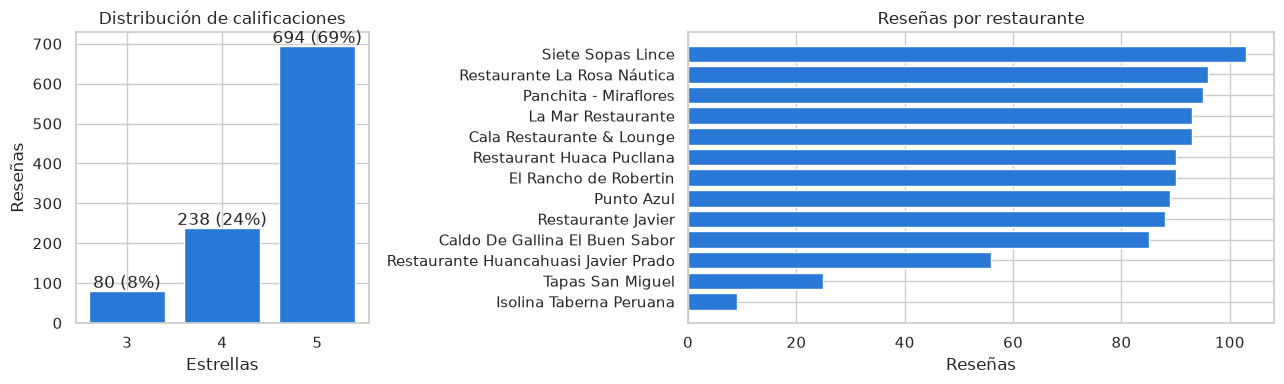

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4), gridspec_kw={"width_ratios": [1, 2]})

conteo = df["calificacion"].value_counts().sort_index()
axes[0].bar(conteo.index.astype(str), conteo.values, color="#2a78d6")
for x, y in zip(conteo.index.astype(str), conteo.values):
    axes[0].text(x, y + 8, f"{y} ({y / len(df):.0%})", ha="center")
axes[0].set_title("Distribución de calificaciones")
axes[0].set_xlabel("Estrellas")
axes[0].set_ylabel("Reseñas")

por_rest = df["restaurante"].value_counts().sort_values()
axes[1].barh(por_rest.index, por_rest.values, color="#2a78d6")
axes[1].set_title("Reseñas por restaurante")
axes[1].set_xlabel("Reseñas")
plt.tight_layout()
plt.show()

**Observaciones:**

- No hay valores nulos ni textos duplicados. Las calificaciones solo toman los valores 3, 4 y 5: 694 reseñas de 5 estrellas (69 %), 238 de 4 (24 %) y 80 de 3 (8 %). No hay reseñas de 1 o 2 estrellas, por lo que el análisis compara reseñas excelentes contra reseñas buenas o regulares, no contra reseñas negativas.
- Diez restaurantes tienen entre 85 y 103 reseñas; *Restaurante Huancahuasi Javier Prado* tiene 56, *Tapas San Miguel* 25 e *Isolina Taberna Peruana* solo 9, por lo que los resultados por restaurante de estos dos últimos son menos confiables.
- *Caldo De Gallina El Buen Sabor* tiene la menor proporción de reseñas de 5 estrellas (45.9 %) y *La Mar Restaurante* la mayor (81.7 %).

## 3. Preprocesamiento

Las técnicas 1 a 4 construyen la cadena de preprocesamiento que usan las demás secciones: oraciones, tokens, tokens sin stopwords y raíces (stems).

### Técnica 1: Segmentación de oraciones (`sent_tokenize`)

`sent_tokenize` divide un texto en oraciones con el modelo Punkt, entrenado para reconocer abreviaturas y signos de puntuación propios de cada idioma. Se usa el modelo para español (`language="spanish"`).

**Caso de uso:** medir el nivel de detalle de cada reseña (número de oraciones) y verificar si los clientes que dan menor calificación escriben reseñas más extensas, para priorizar su lectura.

In [7]:
df["oraciones"] = df["texto"].apply(lambda t: sent_tokenize(t, language="spanish"))
df["n_oraciones"] = df["oraciones"].str.len()

# Ejemplo: segmentación de una reseña de 3 estrellas
ejemplo = df[(df["calificacion"] == 3) & (df["n_oraciones"].between(4, 6))].iloc[0]
print(f"Restaurante: {ejemplo['restaurante']} | "
      f"Calificación: {ejemplo['calificacion']}\n")
for i, oracion in enumerate(ejemplo["oraciones"], 1):
    print(textwrap.fill(f"{i}. {oracion}", width=88, subsequent_indent="   "))

Restaurante: Siete Sopas Lince | Calificación: 3

1. Fila preferencial con niños, atentos y respetuosos, una mala experiencia, ya que no
   tenían el plato que pedí, y al inicio no me anticiparon, el mozo olvidó nuestro
   pedido así que se acabó tuvimos que cambiar de plato 2 veces.
2. Al final nos dieron menos del vuelto ya que pagamos en efectivo, y no nos brindaron
   una solución rápida.
3. Quisieron que esperemos al cuadre de caja .
4. Fatal .


In [8]:
n_or = df["n_oraciones"]
print(f"Oraciones por reseña -> media: {n_or.mean():.2f} | mediana: {n_or.median():.0f} | "
      f"máximo: {n_or.max()}")
print(f"Reseñas de una sola oración: {(n_or == 1).sum()} ({(n_or == 1).mean():.1%})\n")
print(df.groupby("calificacion")["n_oraciones"].agg(["mean", "median", "max"]).round(2))

# Reseñas más detalladas (candidatas a lectura prioritaria)
df.sort_values("n_oraciones", ascending=False)[["restaurante", "calificacion",
                                                "n_oraciones"]].head(5)

Oraciones por reseña -> media: 2.27 | mediana: 2 | máximo: 20
Reseñas de una sola oración: 474 (46.8%)

              mean  median  max
calificacion                   
3             2.40     2.0    7
4             2.46     2.0   20
5             2.19     2.0   17


,restaurante,calificacion,n_oraciones
198,Punto Azul,4,20
9,Siete Sopas Lince,5,17
985,Restaurante Huancahuasi Javier Prado,4,16
802,El Rancho de Robertin,4,14
5,Siete Sopas Lince,4,11


**Interpretación:**

- Punkt separa correctamente las oraciones del ejemplo, incluso con puntos precedidos de espacio (`caja .`, `Fatal .`).
- Las reseñas son cortas: el 46.8 % tiene una sola oración y la mediana es 2 oraciones en las tres calificaciones.
- El promedio de oraciones es algo mayor en 3 estrellas (2.40) y 4 estrellas (2.46) que en 5 estrellas (2.19). La diferencia es pequeña; en la Técnica 2 se ve más clara al medir palabras.
- De las 5 reseñas más detalladas, 4 son de 4 estrellas: los clientes que no dan la nota máxima explican con más detalle lo bueno y lo malo de su visita. Estas reseñas son las primeras que un restaurante debería leer.

### Técnica 2: Tokenización de palabras (`word_tokenize`, `RegexpTokenizer`, `TweetTokenizer`)

La tokenización divide cada oración en unidades (tokens): palabras, números y signos de puntuación. NLTK ofrece varios tokenizadores; se comparan tres sobre un texto real con mayúsculas, letras repetidas, tres emojis seguidos y signos de exclamación repetidos, frecuentes en reseñas informales. Para cumplir el formato del informe, los emojis se imprimen como `<emoji>`.

**Caso de uso:** obtener la lista de palabras de cada reseña (unidad base para el resto del análisis) y elegir el tokenizador que mejor trata el lenguaje informal de los clientes.

In [9]:
# Fragmentos reales de dos reseñas con lenguaje informal
f1 = df.loc[df["texto"].str.contains("RICAAAA"), "texto"].iloc[0]
f2 = df.loc[df["texto"].str.contains("aspiración de aire"), "texto"].iloc[0]
muestra = f1[f1.find("El Pan"):f1.find("soy fan")] + f2[f2.find("recomendado"):]
print("Texto:", sin_simbolos(muestra, "<emoji>"), "\n")

tokenizadores = {
    "word_tokenize": lambda t: word_tokenize(t, language="spanish"),
    "RegexpTokenizer(\\w+)": RegexpTokenizer(r"\w+").tokenize,
    "TweetTokenizer": TweetTokenizer(preserve_case=False, reduce_len=True).tokenize,
}
for nombre, tok in tokenizadores.items():
    tokens_m = [sin_simbolos(t, "<emoji>") for t in tok(muestra)]
    print(textwrap.fill(f"{nombre:22s} {tokens_m}", width=88, subsequent_indent=" " * 23))

Texto: El Pan POR DEOXXX QUE COSA MAS RICAAAA, recomendado <emoji><emoji><emoji> Jueves de Patasca!!! 

word_tokenize          ['El', 'Pan', 'POR', 'DEOXXX', 'QUE', 'COSA', 'MAS', 'RICAAAA',
                       ',', 'recomendado', '<emoji><emoji><emoji>', 'Jueves', 'de',
                       'Patasca', '!', '!', '!']
RegexpTokenizer(\w+)   ['El', 'Pan', 'POR', 'DEOXXX', 'QUE', 'COSA', 'MAS', 'RICAAAA',
                       'recomendado', 'Jueves', 'de', 'Patasca']
TweetTokenizer         ['el', 'pan', 'por', 'deoxxx', 'que', 'cosa', 'mas', 'ricaaa',
                       ',', 'recomendado', '<emoji>', '<emoji>', '<emoji>', 'jueves',
                       'de', 'patasca', '!', '!', '!']


In [10]:
# Tokenización de todas las reseñas con word_tokenize (en minúsculas)
df["tokens"] = df["texto"].apply(lambda t: word_tokenize(t.lower(), language="spanish"))
df["n_tokens"] = df["tokens"].str.len()

todos = [t for ts in df["tokens"] for t in ts]
print(f"Tokens totales: {len(todos):,} | Tipos distintos: {len(set(todos)):,}")
print("\nTokens por reseña según calificación:")
df.groupby("calificacion")["n_tokens"].agg(["mean", "median"]).round(1)

Tokens totales: 31,104 | Tipos distintos: 3,745

Tokens por reseña según calificación:


,mean,median
calificacion,,
3,43.4,32.0
4,36.9,22.5
5,27.2,17.0


**Interpretación:**

- `word_tokenize` separa los signos `!` y la coma, pero deja los tres emojis juntos en un solo token.
- `RegexpTokenizer(r"\w+")` solo conserva caracteres alfanuméricos: pierde la puntuación y los emojis.
- `TweetTokenizer` separa cada emoji en su propio token, pasa a minúsculas y reduce las letras repetidas (`RICAAAA` -> `ricaaa`), útil para texto de redes sociales.
- Se usa `word_tokenize` para todo el corpus porque es coherente con la segmentación Punkt en español; los emojis y la puntuación se filtran en la técnica siguiente.
- El corpus tiene 31,104 tokens y 3,745 tipos distintos. Las reseñas de 3 estrellas tienen en promedio 43.4 tokens, las de 4 estrellas 36.9 y las de 5 estrellas 27.2: **las reseñas de 3 estrellas son 60 % más largas que las de 5**. El cliente satisfecho escribe poco ("Excelente!!"); el que tiene observaciones se extiende.

### Técnica 3: Normalización y eliminación de stopwords (`stopwords.words('spanish')`)

Las *stopwords* son palabras muy frecuentes y con poco contenido (artículos, preposiciones, pronombres). Se eliminan junto con la puntuación y los números para que los conteos reflejen los temas de las reseñas. A la lista de NLTK se agregan palabras del dominio sin información (por ejemplo `restaurante`, `si`, `q`) y se **conservan las negaciones** (`no`, `sin`, `nunca`, `nada`, `ni`), necesarias para el análisis de sentimiento.

**Caso de uso:** reducir el vocabulario a las palabras con contenido (platos, aspectos y adjetivos de opinión).

In [11]:
STOP_NLTK = set(stopwords.words("spanish"))
NEGACIONES = {"no", "sin", "nunca", "nada", "ni"}
STOP_DOMINIO = {"restaurante", "restaurant", "si", "q", "ser", "vez", "así", "tan",
                "va", "hace", "hacer", "puede", "solo", "aunque", "además", "cada",
                "ahí", "ir"}
STOP = (STOP_NLTK | STOP_DOMINIO) - NEGACIONES


def limpiar(tokens):
    # Conserva solo palabras alfabéticas de 2 o más letras que no sean stopwords
    return [t for t in tokens if t.isalpha() and len(t) > 1 and t not in STOP]


df["tokens_alfa"] = df["tokens"].apply(lambda ts: [t for t in ts if t.isalpha()])
df["tokens_lim"] = df["tokens"].apply(limpiar)

alfa = [t for ts in df["tokens_alfa"] for t in ts]
lim = [t for ts in df["tokens_lim"] for t in ts]
print(f"Stopwords de NLTK en español: {len(STOP_NLTK)} | Lista final: {len(STOP)}")
print("Stopwords más frecuentes:", FreqDist(t for t in alfa if t in STOP).most_common(10))
print("\nAntes:  ", " ".join(df.loc[0, "tokens"][:20]))
print("Después:", " ".join(df.loc[0, "tokens_lim"][:12]))

pd.DataFrame({"tokens": [len(todos), len(alfa), len(lim)],
              "vocabulario": [len(set(todos)), len(set(alfa)), len(set(lim))]},
             index=["word_tokenize", "solo palabras", "sin stopwords"])

Stopwords de NLTK en español: 313 | Lista final: 327
Stopwords más frecuentes: [('y', 1111), ('la', 1105), ('de', 1041), ('el', 666), ('muy', 642), ('que', 508), ('es', 457), ('en', 427), ('los', 424), ('para', 420)]

Antes:   delicioso ! 100 % recomendable . sopa criolla , caldo de cordero y patasca , de cortesía dan pan campesino
Después: delicioso recomendable sopa criolla caldo cordero patasca cortesía dan pan campesino rico


,tokens,vocabulario
word_tokenize,31104,3745
solo palabras,26841,3524
sin stopwords,14404,3343


**Interpretación:**

- Al quedarse solo con palabras se pasa de 31,104 a 26,841 tokens. Al quitar stopwords quedan 14,404 tokens: **el 46 % de las palabras de las reseñas son stopwords**.
- El vocabulario apenas baja (de 3,524 a 3,343 tipos, 181 palabras menos): las stopwords son pocas palabras distintas, pero muy repetidas (`y`, `la`, `de`, `el`).
- `muy` (642 apariciones) es la quinta stopword más frecuente; refleja el tono enfático de las reseñas ("muy buena atención").
- En el ejemplo, la reseña queda reducida a sus palabras con contenido: platos (*sopa criolla*, *caldo*, *cordero*, *patasca*), adjetivos (*delicioso*, *recomendable*, *rico*) y aspectos (*cortesía*).

### Técnica 4: Stemming (`SnowballStemmer('spanish')`)

El *stemming* recorta las palabras a su raíz eliminando sufijos (género, número, conjugación, derivación). El algoritmo Snowball para español agrupa formas como *rica, rico, ricos, ricas* en una sola raíz. Es una aproximación por reglas: puede unir palabras distintas o separar formas de la misma palabra.

**Caso de uso:** contar como un mismo concepto las variantes con que los clientes expresan una idea (por ejemplo la recomendación: *recomiendo, recomendable, recomendado*) y reducir el vocabulario para el clasificador.

In [12]:
stemmer = SnowballStemmer("spanish")
df["stems"] = df["tokens_lim"].apply(lambda ts: [stemmer.stem(t) for t in ts])

# Agrupar las palabras originales bajo su raíz
variantes = defaultdict(Counter)
for t in lim:
    variantes[stemmer.stem(t)][t] += 1

fd_stems = FreqDist(s for ts in df["stems"] for s in ts)
reduccion = 1 - len(fd_stems) / len(set(lim))
print(f"Vocabulario sin stopwords: {len(set(lim)):,} | Raíces: {len(fd_stems):,} "
      f"| Reducción: {reduccion:.1%}")

# Familia de la recomendación: Snowball la reparte en tres raíces
for raiz in ["recom", "recomiend", "recomend"]:
    print(f"{raiz:10s} -> {dict(variantes[raiz].most_common(4))}")

filas = [{"raiz": s, "frecuencia": f, "n_variantes": len(variantes[s]),
          "variantes": ", ".join(w for w, _ in variantes[s].most_common(5))}
         for s, f in fd_stems.most_common(10)]
pd.DataFrame(filas)

Vocabulario sin stopwords: 3,343 | Raíces: 2,154 | Reducción: 35.6%
recom      -> {'recomiendo': 79}
recomiend  -> {'recomienda': 4, 'recomiendan': 3}
recomend   -> {'recomendable': 56, 'recomendado': 51, 'recomendación': 4, 'recomendaría': 4}


,raiz,frecuencia,n_variantes,variantes
0,buen,658,5,"buena, buen, bueno, buenos, buenas"
1,com,556,13,"comida, comer, comidas, cómo, come"
2,atencion,402,3,"atención, atencion, atenciones"
3,lug,330,1,lugar
4,excelent,296,2,"excelente, excelentes"
5,plat,232,2,"platos, plato"
6,no,227,1,no
7,ric,160,5,"rico, rica, ricos, ricas, rice"
8,delici,148,7,"deliciosa, delicioso, deliciosos, delicia, deliciosas"
9,ambient,137,6,"ambiente, ambientes, ambientación, ambientado, ambientees"


**Interpretación:**

- El stemming reduce el vocabulario sin stopwords de 3,343 a 2,154 formas (35.6 % menos).
- Agrupa bien las variantes de género y número: `buen` reúne *buena, buen, bueno, buenos, buenas* (658 apariciones) y `delici` reúne *deliciosa, delicioso, deliciosos, delicia*. Además, al quitar tildes une *atención* y *atencion*.
- También comete errores:
  - **Sobre-stemming:** `com` mezcla *comida*, *comer* y *cómo*; `vist` une *vista* con *visto*; `mejor` une *mejor* con *mejorar*.
  - **Sub-stemming:** la recomendación queda dividida en tres raíces (`recom` para *recomiendo*, `recomiend` para *recomienda* y `recomend` para *recomendable/recomendado*) por el cambio de vocal *e/ie* del verbo.
- Para conteos y para el clasificador el resultado es útil, pero los resultados se presentan con las palabras originales porque las raíces no siempre son legibles.

## 4. Análisis de frecuencias y vocabulario

### Técnica 5: Distribución de frecuencias (`FreqDist`)

`FreqDist` cuenta cuántas veces aparece cada token. Permite obtener las palabras más frecuentes, los *hapax* (palabras que aparecen una sola vez) y medidas de diversidad léxica.

**Caso de uso:** identificar los temas que más mencionan los clientes y comparar la diversidad del vocabulario entre restaurantes.

Tokens: 14,404 | Vocabulario: 3,343 | Hapax: 1,944 (58.2% del vocabulario)
Ejemplos de hapax: ['hierba', 'luisa', 'gengibre', 'ingresé', 'creció', 'ususal', 'puntas', 'embarazadas', 'cachangas', 'platano', 'buenaazo', 'disponibilidad']


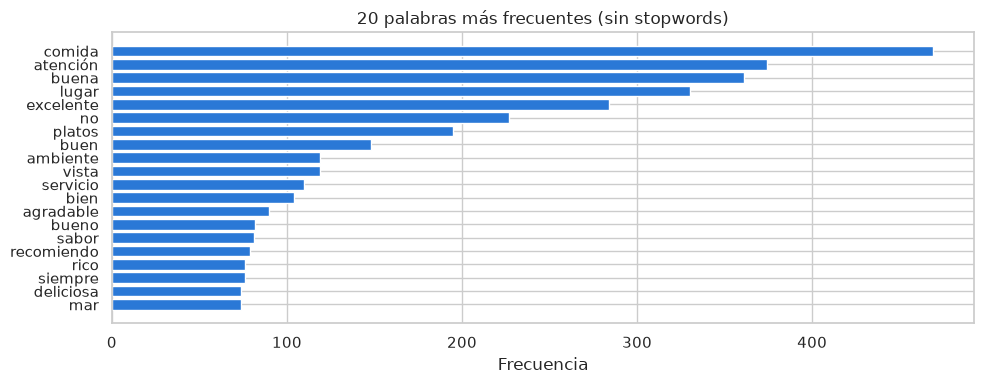

In [13]:
fd = FreqDist(lim)
print(f"Tokens: {fd.N():,} | Vocabulario: {fd.B():,} | Hapax: {len(fd.hapaxes()):,} "
      f"({len(fd.hapaxes()) / fd.B():.1%} del vocabulario)")
print("Ejemplos de hapax:", fd.hapaxes()[:12])

top = fd.most_common(20)
fig, ax = plt.subplots(figsize=(10, 4))
ax.barh([w for w, _ in top][::-1], [c for _, c in top][::-1], color="#2a78d6")
ax.set_title("20 palabras más frecuentes (sin stopwords)")
ax.set_xlabel("Frecuencia")
plt.tight_layout()
plt.show()

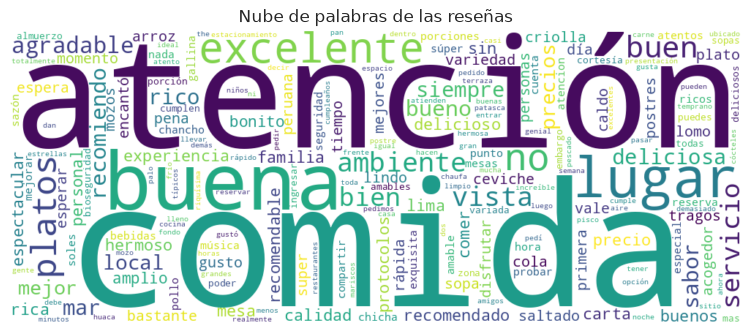

In [14]:
nube = WordCloud(width=1000, height=400, background_color="white", random_state=SEMILLA,
                 colormap="viridis").generate_from_frequencies(fd)
plt.figure(figsize=(11, 3.8))
plt.imshow(nube, interpolation="bilinear")
plt.axis("off")
plt.title("Nube de palabras de las reseñas")
plt.show()

In [15]:
# Diversidad léxica: proporción de palabras distintas en una muestra de 400 tokens
# (la muestra fija evita que los restaurantes con más texto salgan penalizados)
N_MUESTRA = 400
filas = []
for rest, grupo in df.groupby("restaurante"):
    toks = [t for ts in grupo["tokens_lim"] for t in ts]
    if len(toks) >= N_MUESTRA:
        muestra_r = random.Random(SEMILLA).sample(toks, N_MUESTRA)
        filas.append({"restaurante": rest, "tokens": len(toks),
                      "diversidad_lexica": len(set(muestra_r)) / N_MUESTRA,
                      "palabra_top": FreqDist(toks).max()})
pd.DataFrame(filas).sort_values("diversidad_lexica", ascending=False).round(3)

,restaurante,tokens,diversidad_lexica,palabra_top
10,Siete Sopas Lince,1666,0.708,buena
7,Restaurante Huancahuasi Javier Prado,1475,0.695,comida
3,La Mar Restaurante,1215,0.680,comida
0,Cala Restaurante & Lounge,1230,0.665,atención
4,Panchita - Miraflores,1383,0.658,comida
9,Restaurante La Rosa Náutica,1558,0.650,lugar
5,Punto Azul,1038,0.620,comida
8,Restaurante Javier,1067,0.618,atención
6,Restaurant Huaca Pucllana,1199,0.610,comida
2,El Rancho de Robertin,1303,0.598,comida


**Interpretación:**

- Las cinco palabras más frecuentes son *comida* (469), *atención* (374), *buena* (361), *lugar* (330) y *excelente* (284). Los clientes hablan principalmente de tres temas: la comida, la atención y el lugar, y los califican con adjetivos positivos.
- `no` aparece entre las más frecuentes porque se conservó a propósito para el análisis de sentimiento.
- El 58.2 % del vocabulario son *hapax* (1,944 palabras que aparecen una sola vez): nombres de platos poco comunes (*cachangas*), errores de escritura (*ususal*, *gengibre*) y formas expresivas (*buenaazo*). Esto motiva la Técnica 11.
- Diversidad léxica (palabras distintas en una muestra de 400 tokens): *Siete Sopas Lince* (0.708) y *Huancahuasi* (0.695) tienen las reseñas más variadas, posiblemente porque sus cartas tienen muchos platos (sopas distintas cada día, platos de la sierra). *Caldo De Gallina El Buen Sabor* (0.592) y *El Rancho de Robertin* (0.598) son las menos variadas; posiblemente porque sus reseñas giran alrededor de un plato principal (caldo de gallina, chancho al palo). *Tapas San Miguel* e *Isolina* no se incluyen por tener menos de 400 tokens.

### Técnica 6: Distribución de frecuencias condicional (`ConditionalFreqDist`)

Una `ConditionalFreqDist` guarda una distribución de frecuencias para cada condición. Se usan dos condiciones: la calificación de la reseña (3, 4 o 5 estrellas) y el restaurante. Como cada grupo tiene distinto tamaño, las frecuencias se expresan por cada 1,000 tokens.

**Caso de uso:** encontrar las palabras características de las reseñas con menor calificación (problemas que reportan los clientes) y ver en qué restaurantes se concentran.

In [16]:
cfd = ConditionalFreqDist((c, t) for c, ts in zip(df["calificacion"], df["tokens_lim"])
                          for t in ts)
for c in sorted(cfd.conditions()):
    top = [w for w, _ in cfd[c].most_common(8)]
    print(f"{c} estrellas: {cfd[c].N():>6,} tokens | top: {top}")

3 estrellas:  1,551 tokens | top: ['no', 'comida', 'buena', 'lugar', 'sabor', 'platos', 'atención', 'bien']
4 estrellas:  4,108 tokens | top: ['comida', 'buena', 'atención', 'no', 'platos', 'lugar', 'excelente', 'agradable']
5 estrellas:  8,745 tokens | top: ['comida', 'atención', 'lugar', 'excelente', 'buena', 'platos', 'buen', 'vista']


In [17]:
# Palabras sobrerrepresentadas en 3 estrellas respecto de 5 estrellas
# (frecuencia por 1,000 tokens; suavizado +1 para evitar división entre cero)
def por_mil(c, w):
    return 1000 * cfd[c][w] / cfd[c].N()


filas = []
for w in cfd[3]:
    if cfd[3][w] >= 5:
        r3 = 1000 * (cfd[3][w] + 1) / cfd[3].N()
        r5 = 1000 * (cfd[5][w] + 1) / cfd[5].N()
        filas.append({"palabra": w, "frec_3": cfd[3][w], "x1000_3": por_mil(3, w),
                      "x1000_4": por_mil(4, w), "x1000_5": por_mil(5, w),
                      "ratio_3_vs_5": r3 / r5})
caract3 = pd.DataFrame(filas).sort_values("ratio_3_vs_5", ascending=False).round(2)
caract3.head(10)

,palabra,frec_3,x1000_3,x1000_4,x1000_5,ratio_3_vs_5
23,mal,7,4.51,0.00,0.11,22.55
14,ni,9,5.80,0.73,0.34,14.10
38,normal,5,3.22,0.49,0.23,11.28
40,embargo,5,3.22,2.43,0.34,8.46
11,pollo,10,6.45,1.22,0.91,6.89
21,soles,8,5.16,1.70,0.80,6.34
16,chancho,9,5.80,1.22,0.91,6.26
35,porción,5,3.22,2.19,0.57,5.64
22,nada,7,4.51,2.68,0.91,5.01
51,semana,5,3.22,1.46,0.69,4.83


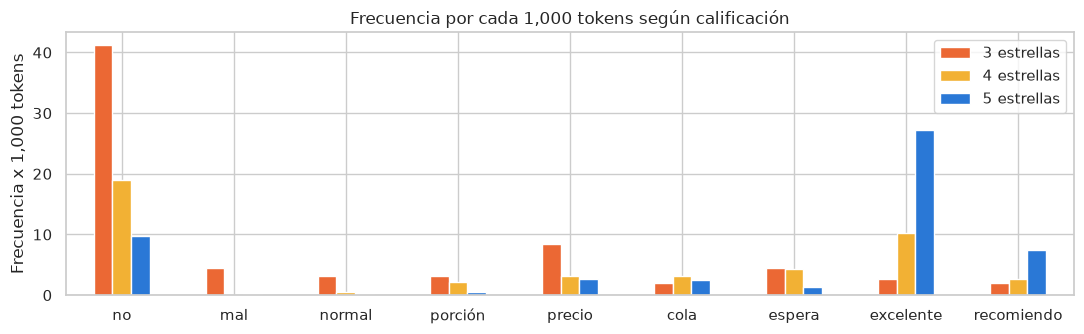

In [18]:
palabras = ["no", "mal", "normal", "porción", "precio", "cola", "espera", "excelente",
            "recomiendo"]
tabla6 = pd.DataFrame({c: [por_mil(c, w) for w in palabras] for c in [3, 4, 5]},
                      index=palabras).round(2)
tabla6.columns = ["3 estrellas", "4 estrellas", "5 estrellas"]

tabla6.plot(kind="bar", figsize=(11, 3.5), color=["#eb6834", "#f2b134", "#2a78d6"])
plt.title("Frecuencia por cada 1,000 tokens según calificación")
plt.ylabel("Frecuencia x 1,000 tokens")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [19]:
# Frecuencia condicional por restaurante (conteos absolutos)
cfd_rest = ConditionalFreqDist((r, t) for r, ts in zip(df["restaurante"], df["tokens_lim"])
                               for t in ts)
cfd_rest.tabulate(samples=["cola", "espera", "precio", "vista", "ambiente", "atención"])

# Reseñas que mencionan "cola", por restaurante y calificación
cola = df[df["tokens_alfa"].apply(lambda ts: "cola" in ts)]
print("\nReseñas que mencionan 'cola':")
print(pd.crosstab(cola["restaurante"], cola["calificacion"], margins=True,
                  margins_name="total"))

                                         cola   espera   precio    vista ambiente atención 
           Cala Restaurante & Lounge        0        1        2       26       16       46 
      Caldo De Gallina El Buen Sabor        1        1        9        0        1       20 
               El Rancho de Robertin        2        1        7        0       13       33 
             Isolina Taberna Peruana        1        1        1        0        2        4 
                  La Mar Restaurante        1        3        6        1        9       34 
               Panchita - Miraflores        0        6        4        0        9       32 
                          Punto Azul        0        1        3        0        8       32 
           Restaurant Huaca Pucllana        0        5        3       23       14       31 
Restaurante Huancahuasi Javier Prado        3        3        6        0       14       27 
                  Restaurante Javier        7        5        2       32        

**Interpretación:**

- `no` es la palabra más frecuente en las reseñas de 3 estrellas: 41.3 por cada 1,000 tokens, frente a 19.0 en 4 estrellas y 9.7 en 5 estrellas (4.2 veces más que en 5 estrellas).
- Las palabras sobrerrepresentadas en 3 estrellas describen quejas: *mal*, *ni*, *normal*, *sin embargo* (`embargo`), *nada*, y aspectos concretos: *porción*, *soles* (precio en soles) y platos como *pollo* y *chancho*.
- *precio* aparece 8.4 veces por cada 1,000 tokens en 3 estrellas frente a 2.7 en 5 estrellas, y *espera* 4.5 frente a 1.4. En cambio, *excelente* (27.2) y *recomiendo* (7.4) se concentran en 5 estrellas.
- *cola* no se concentra en 3 estrellas (1.9 frente a 2.5 en 5 estrellas). Por restaurante, 21 de las 37 reseñas que mencionan la cola son de *Siete Sopas Lince*, y de esas 21, 14 son de 5 estrellas, 6 de 4 y 1 de 3: los clientes mencionan la cola, pero la aceptan si la comida lo vale.
- *vista* se concentra en *La Rosa Náutica* (36), *Restaurante Javier* (32), *Cala* (26) y *Huaca Pucllana* (23), los locales con vista al mar o a la huaca.

### Técnica 7: N-gramas y colocaciones (`ngrams`, `BigramCollocationFinder`, `TrigramCollocationFinder`)

Un n-grama es una secuencia de *n* palabras consecutivas. Una colocación es un n-grama que aparece junto más de lo que se esperaría por azar; se mide con estadísticos como la información mutua puntual (PMI) o la razón de verosimilitud (*likelihood ratio*). Los buscadores se construyen con `from_documents` para no unir palabras de reseñas distintas.

**Caso de uso:** detectar automáticamente los platos y expresiones más mencionados. Los platos con preposición (*caldo de gallina*, *ají de gallina*) se buscan como trigramas sobre el texto que conserva las stopwords.

In [20]:
# Bigramas más frecuentes (sin stopwords, dentro de cada reseña)
bigramas = FreqDist(bg for ts in df["tokens_lim"] for bg in ngrams(ts, 2))
print("Bigramas más frecuentes:")
print(", ".join(f"{' '.join(bg)} ({f})" for bg, f in bigramas.most_common(12)))

bam = BigramAssocMeasures()
finder2 = BigramCollocationFinder.from_documents(df["tokens_lim"])
finder2.apply_freq_filter(5)  # solo pares que aparecen al menos 5 veces

col_pmi = finder2.nbest(bam.pmi, 12)
col_lr = finder2.nbest(bam.likelihood_ratio, 12)
pd.DataFrame({"PMI": [" ".join(b) for b in col_pmi],
              "Likelihood ratio": [" ".join(b) for b in col_lr]})

Bigramas más frecuentes:
buena atención (105), buena comida (69), excelente atención (54), excelente lugar (50), comida buena (45), comida deliciosa (44), atención buena (40), excelente comida (37), vista mar (36), comida rica (28), buen lugar (28), vale pena (27)


,PMI,Likelihood ratio
0,papa huancaina,buena atención
1,aire libre,vale pena
2,pisco sour,lomo saltado
3,huaca pucllana,vista mar
4,fines semana,caldo gallina
5,chicha morada,chancho palo
6,chancho palo,comida deliciosa
7,punto azul,sin embargo
8,fin semana,buena comida
9,todas medidas,punto azul


In [21]:
# Trigramas de la forma <palabra> de <palabra>: nombres de platos con preposición
tam = TrigramAssocMeasures()
finder3 = TrigramCollocationFinder.from_documents(df["tokens_alfa"])
finder3.apply_freq_filter(3)
finder3.apply_ngram_filter(lambda w1, w2, w3: w2 != "de" or w1 in STOP or w3 in STOP)

trigramas = [(" ".join(t), finder3.ngram_fd[t], round(score, 1))
             for t, score in finder3.score_ngrams(tam.likelihood_ratio)]
pd.DataFrame(sorted(trigramas, key=lambda x: (-x[1], x[0]))[:10],
             columns=["trigrama", "frecuencia", "likelihood_ratio"])

,trigrama,frecuencia,likelihood_ratio
0,caldo de gallina,20,443.8
1,protocolos de bioseguridad,9,227.7
2,protocolos de seguridad,9,214.4
3,variedad de platos,9,159.5
4,atención de primera,8,155.4
5,fines de semana,8,233.1
6,platos de fondo,8,128.6
7,tiempo de espera,8,146.9
8,fin de semana,5,175.7
9,chicha de jora,4,88.1


**Interpretación:**

- Los bigramas más frecuentes son valoraciones: *buena atención* (105), *buena comida* (69), *excelente atención* (54), *excelente lugar* (50).
- PMI prioriza pares que casi siempre aparecen juntos: platos y bebidas (*papa huancaína*, *pisco sour*, *chicha morada*, *chancho palo*, *caldo gallina*, *lomo saltado*), lugares (*huaca pucllana*, *aire libre*) y nombres (*punto azul*).
- Likelihood ratio prioriza pares frecuentes y asociados: además de las valoraciones, detecta *vista mar*, *lomo saltado*, *caldo gallina* y *chancho palo*.
- Los trigramas `<palabra> de <palabra>` recuperan el nombre completo de platos como *caldo de gallina* (20) y *chicha de jora* (4). También aparecen expresiones que no son platos (*protocolos de bioseguridad*, *tiempo de espera*, *platos de fondo*), por lo que la lista requiere una revisión final.

### Técnica 8: Concordancia y contexto (`nltk.Text`)

`nltk.Text` envuelve una lista de tokens y ofrece herramientas de lectura en contexto: `concordance_list` devuelve cada aparición de una palabra con el texto que la rodea, `similar` lista palabras que aparecen en contextos parecidos, `common_contexts` muestra los contextos que comparten dos palabras y `dispersion_plot` grafica la posición de cada aparición en el corpus.

**Caso de uso:** leer qué dicen los clientes sobre la cola, el precio y la atención. Las reseñas se ordenan de menor a mayor calificación y se separan con el token `|` para que los contextos no mezclen dos reseñas sin que se note; así cada línea de concordancia se puede asociar a su calificación.

In [22]:
SEP = "|"
orden = df.sort_values("calificacion", kind="stable")
tokens_corpus = [t for ts in orden["tokens"] for t in ts + [SEP]]
corpus = Text(tokens_corpus, name="Reseñas CityPeru")

# Posición final de cada grupo de calificación en el corpus ordenado
limites = (orden["n_tokens"] + 1).groupby(orden["calificacion"]).sum().cumsum()


def calificacion_en(posicion):
    return next(c for c, fin in limites.items() if posicion < fin)


for palabra in ["cola", "precio"]:
    total = len(corpus.concordance_list(palabra, lines=10_000))
    print(f"Concordancia de '{palabra}' ({total} apariciones, primeras 7):")
    for linea in corpus.concordance_list(palabra, width=80, lines=7):
        print(f"  [{calificacion_en(linea.offset)} est.] {linea.line}")
    print()

Concordancia de 'cola' (38 apariciones, primeras 7):
  [3 est.] , 2 aspectos que hay que mejorar ; la cola de ingreso , que sigue siendo insufri
  [3 est.] a que haya asueto , tendrás que hacer cola para ingresar ; el lugar estaba reple
  [3 est.]  cantidad de gente . tienes que hacer cola para que te den un ticket y te pongan
  [4 est.] rsonal muy buena | local amplio , hay cola para entrar en las horas puntas va de
  [4 est.] buena experiencia , salvo por la gran cola . | agradable experiencia . reciben c
  [4 est.] ry , por lo que reducen como a 4 y la cola para acceder al local por la alta dem
  [4 est.] alemente . fui un domingo y había una cola increible , yo igual iba para deliver

Concordancia de 'precio' (50 apariciones, primeras 7):
  [3 est.] l postre mejor dos platos y listo el precio es medio alto | rescato el sabor de 
  [3 est.]  pero , para mí gusto , no merece el precio que tiene . hay muchos otros restaur
  [3 est.]  ( o incluso mejor ) por la mitad de precio . lo que

In [23]:
print("Palabras usadas en contextos similares a 'atención':")
corpus.similar("atención", num=15)
print("\nContextos comunes de 'comida' y 'atención':")
corpus.common_contexts(["comida", "atención"], num=10)

Palabras usadas en contextos similares a 'atención':
comida carta vista experiencia calidad pena lugar servicio sazón
atencion y mesa patasca música zona

Contextos comunes de 'comida' y 'atención':
la_es la_muy la_y buena_y excelente_y la_excelente la_de la_buena
la_el buena_buena


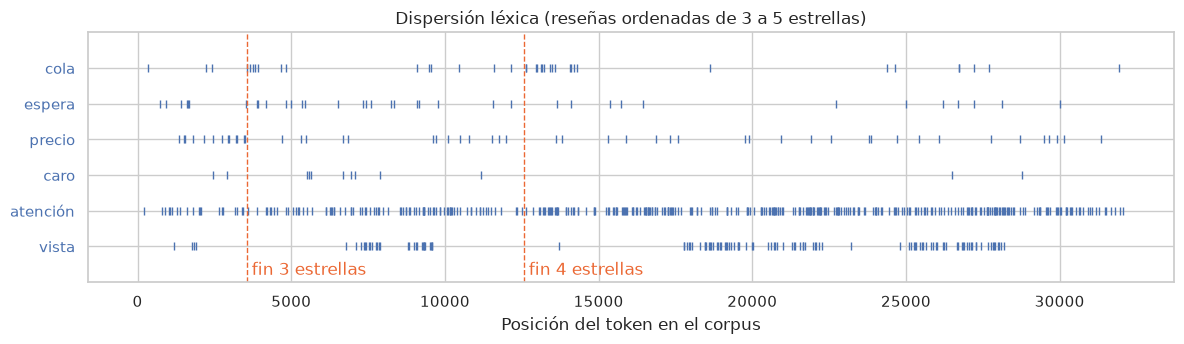

,cola,espera,precio,caro,atención,vista
3 estrellas,0.86,2.02,3.74,0.58,5.76,1.15
4 estrellas,1.48,2.05,1.48,0.91,9.91,3.08
5 estrellas,1.17,0.64,1.27,0.11,14.16,4.67


In [24]:
palabras_disp = ["cola", "espera", "precio", "caro", "atención", "vista"]
titulo = "Dispersión léxica (reseñas ordenadas de 3 a 5 estrellas)"
ax = dispersion_plot(corpus, palabras_disp, title=titulo)
ax.figure.set_size_inches(12, 3.6)
for c, x in limites.iloc[:-1].items():
    ax.axvline(x, color="#eb6834", linestyle="--", linewidth=1)
    ax.text(x, -0.8, f" fin {c} estrellas", color="#eb6834")
ax.set_xlabel("Posición del token en el corpus")
plt.tight_layout()
plt.show()

# Frecuencia por cada 1,000 tokens según calificación (lectura cuantitativa del gráfico)
fd_cal = {c: FreqDist(t for ts in g["tokens"] for t in ts) for c, g in df.groupby("calificacion")}
pd.DataFrame({f"{c} estrellas": [1000 * f[w] / f.N() for w in palabras_disp]
              for c, f in fd_cal.items()}, index=palabras_disp).round(2).T

**Interpretación:**

- Las primeras líneas de la concordancia de *cola* son de reseñas de 3 y 4 estrellas: "la cola de ingreso, que sigue siendo insufrible", "tendrás que hacer cola para ingresar", "hay cola para entrar en las horas punta". Las 7 primeras líneas de *precio* son de 3 estrellas y muestran el tipo de queja: "no merece el precio que tiene", "por la mitad de precio", "por ese precio la carapulcra con la porción de arroz...". El problema no es solo el precio, sino la relación precio-porción.
- `similar("atención")` devuelve *comida, carta, vista, experiencia, calidad, lugar, servicio, sazón*: palabras que los clientes califican con las mismas construcciones ("la ___ es excelente"). Los contextos comunes de *comida* y *atención* (`la_es`, `la_muy`, `buena_y`, `excelente_y`) lo confirman. El separador `|` evita que estos contextos se formen con el final de una reseña y el inicio de otra.
- La tabla de frecuencias por 1,000 tokens permite leer el gráfico de dispersión con precisión:
  - *precio* destaca solo en 3 estrellas (3.74, frente a 1.48 en 4 y 1.27 en 5).
  - *espera* es igual de frecuente en 3 y 4 estrellas (2.02 y 2.05) y baja en 5 estrellas (0.64); *caro* casi no aparece en 5 estrellas (0.11).
  - *atención* (5.76 / 9.91 / 14.16) y *vista* (1.15 / 3.08 / 4.67) aumentan con la calificación: se concentran en las reseñas de 5 estrellas.
  - *cola* tiene frecuencias similares en los tres grupos (0.86 / 1.48 / 1.17).

## 5. Análisis gramatical, ortográfico y semántico

### Técnica 9: Etiquetado gramatical (POS) con etiquetadores entrenados (`UnigramTagger`, `BigramTagger`, `RegexpTagger`)

El etiquetado gramatical (*part-of-speech tagging*) asigna a cada palabra su categoría: sustantivo, adjetivo, verbo, etc. NLTK no incluye un etiquetador preentrenado para español, por lo que se entrena uno con el corpus `cess_esp` (≈6,000 oraciones de noticias anotadas). Se usa una cadena de *backoff*: el `BigramTagger` usa la etiqueta anterior como contexto; si no conoce el caso, pasa al `UnigramTagger` (etiqueta más frecuente de la palabra) y luego a un `RegexpTagger` con sufijos del español (`-mente` adverbio, `-ción` sustantivo, `-oso` adjetivo...).

Las etiquetas EAGLES de `cess_esp` (por ejemplo `ncms000`, `aq0fs0`) se simplifican a sus dos primeros caracteres: `nc` sustantivo común, `aq` adjetivo, `vm` verbo, `sp` preposición, `rg` adverbio, `da` artículo.

**Caso de uso:** obtener los sustantivos (de qué hablan los clientes) y adjetivos (cómo lo califican) más usados en las reseñas.

In [25]:
def simplificar(oracion):
    # Minúsculas, etiqueta de 2 caracteres y sin elementos vacíos (*0*)
    return [(w.lower(), t[:2].lower()) for w, t in oracion if w != "*0*"]


oraciones_cess = [simplificar(s) for s in cess_esp.tagged_sents()]
random.Random(SEMILLA).shuffle(oraciones_cess)
corte = int(len(oraciones_cess) * 0.9)
train_pos, test_pos = oraciones_cess[:corte], oraciones_cess[corte:]
print(f"Oraciones cess_esp -> entrenamiento: {len(train_pos)} | prueba: {len(test_pos)}")

patrones = [
    (r"^-?\d+([.,/]\d+)?$", "z"),                                # números
    (r".*mente$", "rg"),                                         # adverbios
    (r".*(ción|sión|dad|miento)s?$", "nc"),                      # sustantivos derivados
    (r".*(oso|osa|ble|ivo|iva|ísimo|ísima|ico|ica)s?$", "aq"),   # adjetivos
    (r".*(ando|iendo|aron|ieron|aba|aban|amos|imos)$", "vm"),    # gerundios y pasados
    (r".*(ar|er|ir)$", "vm"),                                    # infinitivos
    (r".*(ado|ido|ada|ida)s?$", "aq"),                           # participios
    (r".*", "nc"),                                               # por defecto
]
t_default = DefaultTagger("nc")
t_regexp = RegexpTagger(patrones)
t_uni = UnigramTagger(train_pos, backoff=t_regexp)
t_bi = BigramTagger(train_pos, backoff=t_uni)

pd.DataFrame({"etiquetador": ["DefaultTagger('nc')", "RegexpTagger", "Unigram + Regexp",
                              "Bigram + Unigram + Regexp"],
              "accuracy_test": [t.accuracy(test_pos)
                                for t in [t_default, t_regexp, t_uni, t_bi]]}).round(4)

Oraciones cess_esp -> entrenamiento: 5427 | prueba: 603


,etiquetador,accuracy_test
0,DefaultTagger('nc'),0.1753
1,RegexpTagger,0.2243
2,Unigram + Regexp,0.9105
3,Bigram + Unigram + Regexp,0.9269


In [26]:
# Etiquetado de las reseñas oración por oración
def etiquetar(oraciones):
    return [t_bi.tag(word_tokenize(o.lower(), language="spanish")) for o in oraciones]


df["pos"] = df["oraciones"].apply(etiquetar)
etiquetas = [(w, t) for doc in df["pos"] for o in doc for w, t in o]
print("Ejemplo:", df.loc[1, "pos"][1][:16])
print("\nEtiquetas más frecuentes:", FreqDist(t for _, t in etiquetas).most_common(8))

sustantivos = FreqDist(w for w, t in etiquetas
                       if t == "nc" and w.isalpha() and w not in STOP)
adjetivos = FreqDist(w for w, t in etiquetas if t == "aq" and w.isalpha())

# Adjetivos más usados según calificación
adj_cal = ConditionalFreqDist((c, w) for c, doc in zip(df["calificacion"], df["pos"])
                              for o in doc for w, t in o if t == "aq" and w.isalpha())
for c in [3, 4, 5]:
    print(f"Adjetivos {c} estrellas: {[w for w, _ in adj_cal[c].most_common(10)]}")

pd.DataFrame({"sustantivo": [w for w, _ in sustantivos.most_common(10)],
              "frec_s": [c for _, c in sustantivos.most_common(10)],
              "adjetivo": [w for w, _ in adjetivos.most_common(10)],
              "frec_a": [c for _, c in adjetivos.most_common(10)]})

Ejemplo: [('en', 'sp'), ('cuanto', 'rg'), ('a', 'sp'), ('la', 'da'), ('atención', 'nc'), ('buena', 'aq'), (',', 'fc'), ('la', 'da'), ('comida', 'nc'), ('estaba', 'vm'), ('rica', 'aq'), (',', 'fc'), ('me', 'pp'), ('encantaron', 'vm'), ('las', 'da'), ('cachangas', 'nc')]

Etiquetas más frecuentes: [('nc', 8351), ('aq', 3465), ('sp', 3244), ('da', 2480), ('vm', 2353), ('fp', 1580), ('fc', 1575), ('rg', 1551)]
Adjetivos 3 estrellas: ['buena', 'bueno', 'buen', 'local', 'mejor', 'mejores', 'rico', 'normal', 'bonito', 'agradable']
Adjetivos 4 estrellas: ['buena', 'excelente', 'agradable', 'bueno', 'buen', 'rico', 'buenos', 'local', 'solo', 'amplio']
Adjetivos 5 estrellas: ['excelente', 'buena', 'buen', 'deliciosa', 'rico', 'recomendable', 'agradable', 'espectacular', 'mejor', 'hermoso']


,sustantivo,frec_s,adjetivo,frec_a
0,comida,469,buena,361
1,atención,374,excelente,284
2,lugar,330,buen,148
3,platos,195,agradable,90
4,ambiente,119,bueno,82
5,vista,119,rico,76
6,servicio,110,deliciosa,74
7,sabor,81,mejor,59
8,mar,74,recomendable,57
9,precios,71,rica,55


**Interpretación:**

- Sobre las oraciones de prueba de `cess_esp`, la cadena completa alcanza 92.7 % de exactitud, frente a 17.5 % del etiquetador por defecto y 91.1 % del unigrama. El bigrama aporta poco porque la mayor parte del acierto viene de conocer la palabra.
- Esta exactitud se mide sobre noticias; en las reseñas debe ser menor, porque tienen lenguaje informal y palabras ausentes en `cess_esp`. En el ejemplo se etiquetan bien *atención/nc buena/aq*, *rica/aq* y *encantaron/vm*.
- Sustantivos más usados: *comida*, *atención*, *lugar*, *platos*, *ambiente*, *vista*, *servicio*, *sabor*, *precios*. Adjetivos: *buena*, *excelente*, *buen*, *agradable*, *rico*, *deliciosa*, *recomendable*.
- Error visible: *local* aparece como adjetivo (53), cuando en las reseñas casi siempre es sustantivo ("el local es amplio").
- Por calificación, en 3 estrellas aparece *normal* entre los adjetivos más usados, mientras que en 5 estrellas aparecen *deliciosa*, *recomendable*, *espectacular* y *hermoso*: el cliente de 3 estrellas califica la experiencia como correcta pero no sobresaliente.

### Técnica 10: Chunking para extraer pares aspecto-opinión (`RegexpParser`)

El *chunking* agrupa secuencias de palabras etiquetadas en frases según una gramática de expresiones regulares sobre las etiquetas POS. Se definen dos patrones:

- `OPINION`: sustantivo seguido de adjetivo, con adverbio opcional (*comida rica*, *atención muy buena*) o adjetivo antes del sustantivo (*buena atención*).
- `COMPUESTO`: sustantivo + preposición + sustantivo; se conservan los que usan `de` (*caldo de gallina*).

**Caso de uso:** obtener automáticamente qué opinan los clientes sobre cada aspecto (pares aspecto-adjetivo) y comparar las opiniones de las reseñas de 3 estrellas con las de 5.

In [27]:
gramatica = r'''
  COMPUESTO: {<nc><sp><nc>}
  OPINION:   {<nc><rg>?<aq>}
             {<aq><nc>}
'''
chunker = RegexpParser(gramatica)

# Chunks encontrados en una oración de ejemplo
arbol = chunker.parse(df.loc[1, "pos"][1])
for st in arbol.subtrees(lambda t: t.label() != "S"):
    print(f"{st.label():10s} {' '.join(f'{w}/{t}' for w, t in st.leaves())}")

OPINION    atención/nc buena/aq
COMPUESTO  rellenas/nc de/sp platano/nc
OPINION    tallarin/nc verde/aq
COMPUESTO  pancito/nc de/sp cortesia/nc
COMPUESTO  caldo/nc de/sp gallina/nc


In [28]:
def extraer_chunks(doc):
    # Devuelve pares (aspecto, opinión) y nombres compuestos de una reseña etiquetada
    pares, compuestos = [], []
    for o in doc:
        for st in chunker.parse(o).subtrees():
            hojas = st.leaves()
            if st.label() == "OPINION":
                nombre = [w for w, t in hojas if t == "nc"][0]
                adj = [w for w, t in hojas if t == "aq"][0]
                if nombre.isalpha() and adj.isalpha():
                    pares.append((nombre, adj))
            elif st.label() == "COMPUESTO" and hojas[1][0] == "de":
                compuestos.append(" ".join(w for w, _ in hojas))
    return pares, compuestos


df[["pares", "compuestos"]] = df["pos"].apply(lambda d: pd.Series(extraer_chunks(d)))
todos_pares = Counter(p for ps in df["pares"] for p in ps)
print(f"Pares aspecto-opinión extraídos: {sum(todos_pares.values()):,}")
print(textwrap.fill("Más frecuentes: " + ", ".join(
    f"{n} {a} ({c})" for (n, a), c in todos_pares.most_common(15)), width=88))
pares3 = Counter(p for ps in df.loc[df["calificacion"] == 3, "pares"] for p in ps)
print(textwrap.fill("3 estrellas: " + ", ".join(
    f"{n} {a}" for (n, a), _ in pares3.most_common(25)), width=88))
print("Nombres compuestos con 'de':",
      Counter(c for cs in df["compuestos"] for c in cs).most_common(6))

# Adjetivos asociados a cada aspecto principal
filas = []
for asp in ["comida", "atención", "servicio", "lugar", "ambiente", "precios", "platos"]:
    adjs = Counter({a: c for (n, a), c in todos_pares.items() if n == asp})
    top_adj = ", ".join(f"{a} ({c})" for a, c in adjs.most_common(5))
    filas.append({"aspecto": asp, "pares": sum(adjs.values()), "adjetivos más usados": top_adj})
pd.DataFrame(filas)

Pares aspecto-opinión extraídos: 1,714
Más frecuentes: atención buena (110), comida buena (72), lugar excelente (48), comida
deliciosa (47), atención excelente (44), comida excelente (30), comida rica (25), lugar
buen (25), lugar hermoso (25), servicio buen (23), servicio excelente (22), ambiente
buen (21), sabor buen (15), atención rápida (15), lugar bonito (15)
3 estrellas: atención buena, comida buena, experiencia mala, lugar buen, lugar bonito,
atención rápida, sabor buen, porción buena, temperatura buena, queja pequeña, solución
rápida, criolla normal, fetuccini igual, zona alejada, visita anterior, impresión buena,
an dado, comida típica, lugar perfecto, platos elementales, lugar bueno, ambiente
agradable, ceviche agradable, piña colada, licor igual
Nombres compuestos con 'de': [('caldo de gallina', 19), ('protocolos de seguridad', 9), ('protocolos de bioseguridad', 9), ('variedad de platos', 9), ('platos de fondo', 8), ('tiempo de espera', 8)]


,aspecto,pares,adjetivos más usados
0,comida,232,"buena (72), deliciosa (47), excelente (30), rica (25), peruana (14)"
1,atención,204,"buena (110), excelente (44), rápida (15), esmerada (6), genial (3)"
2,servicio,63,"buen (23), excelente (22), bueno (4), gran (2), impecable (2)"
3,lugar,196,"excelente (48), buen (25), hermoso (25), bonito (15), agradable (14)"
4,ambiente,69,"buen (21), agradable (14), excelente (10), cálido (3), festivo (3)"
5,precios,27,"razonables (8), accesibles (5), buenos (4), acordes (3), elevados (3)"
6,platos,50,"buenos (8), deliciosos (7), típicos (6), variados (4), mejores (4)"


**Interpretación:**

- En la oración de ejemplo, la gramática encuentra *atención buena* (opinión) y *caldo de gallina* (plato). También comete errores: *tallarín verde* es un plato y no una opinión, y *rellenas de plátano* sale como nombre compuesto porque el etiquetador marcó *rellenas* como sustantivo.
- Se extraen 1,714 pares aspecto-opinión. Los más frecuentes: *atención buena* (110), *comida buena* (72), *lugar excelente* (48), *comida deliciosa* (47), *atención excelente* (44). Los pares con el adjetivo antes del sustantivo se normalizan como (sustantivo, adjetivo): "buen lugar" queda como *lugar buen*.
- La tabla por aspecto resume la opinión de los clientes: la atención es *buena*, *excelente* y *rápida*; el lugar es *excelente*, *hermoso*, *bonito*; los precios son *razonables* (8) y *accesibles* (5), aunque también aparece *elevados* (3).
- En las reseñas de 3 estrellas aparecen pares negativos o neutros que no salen en el total: *experiencia mala*, *criolla normal* (sopa criolla), *platos elementales*, *queja pequeña*, *zona alejada*.
- Otros errores: *comida típica* y *piña colada* son descripciones y no opiniones, y *an dado* viene de un error de escritura ("an" por "han"). Los errores del etiquetador se trasladan al chunking.

### Técnica 11: Distancia de edición para detectar errores ortográficos (`edit_distance`)

La distancia de edición (Levenshtein) es el número mínimo de inserciones, eliminaciones o sustituciones de caracteres para convertir una palabra en otra; con `transpositions=True` también cuenta el intercambio de dos letras contiguas. Se usa para relacionar palabras poco frecuentes con palabras frecuentes muy parecidas.

Se aplican dos reglas:

1. **Tilde:** una palabra sin tilde cuya forma con tilde es más frecuente en el corpus (*atencion* -> *atención*). Se excluyen las palabras que también son stopwords válidas sin tilde (*esta/está*; *mas/más* queda fuera porque la referencia exige 4 o más letras).
2. **Edición:** una palabra cuya raíz no existe en un diccionario auxiliar (vocabulario de `cess_esp` y del WordNet en español) y que está a distancia 1 de una palabra frecuente (2 si tiene 9 o más letras). Se descartan candidatos con la misma raíz Snowball (*ceviches* y *ceviche* no son un error) y palabras en inglés.

La variante *cebiche* es una grafía aceptada por la RAE y no un error; se marca como **variante** y se unifica con *ceviche*, la forma más usada en las reseñas, solo para que los conteos no se dividan.

**Caso de uso:** detectar palabras mal escritas o sin tilde en las reseñas (*atencion*, *exelente*) y unificarlas. El resultado se guarda en una columna nueva (`tokens_corr`) que usan las técnicas siguientes (12 WordNet, 13 TF-IDF y 14 Naive Bayes); las técnicas 1 a 10 trabajan con el texto original.

In [29]:
fd_alfa = FreqDist(alfa)
referencia = [w for w, f in fd_alfa.items() if f >= 8 and len(w) >= 4]


def sin_tildes(p):
    return "".join(c for c in unicodedata.normalize("NFD", p)
                   if unicodedata.category(c) != "Mn")


# Diccionario auxiliar: raíces de las palabras de cess_esp y del WordNet en español.
# Sirve para no "corregir" palabras válidas que simplemente son poco frecuentes.
dic_es = {w.lower() for w in cess_esp.words() if w.isalpha()}
dic_es |= {l.lower() for l in wn.all_lemma_names(lang="spa") if l.isalpha()}
raices_dic = {stemmer.stem(w) for w in dic_es}
STOP_EN = set(stopwords.words("english"))
VARIANTES = {"cebiche", "cebiches"}  # grafías aceptadas por la RAE


def es_ingles(p):
    return p in STOP_EN or bool(wn.synsets(p))


# Regla 1: palabra sin tilde cuya versión con tilde es más frecuente (atencion -> atención)
reg_tilde = {}
for w in fd_alfa:
    if w == sin_tildes(w) and w not in STOP:
        for ref in referencia:
            if ref != w and sin_tildes(ref) == w and fd_alfa[ref] > fd_alfa[w]:
                reg_tilde[w] = ref


# Regla 2: palabra desconocida a distancia 1 (2 si tiene 9+ letras) de una palabra frecuente
def sugerir(palabra):
    max_dist = 1 if len(palabra) < 9 else 2
    mejores = []
    for ref in referencia:
        # Prefiltro: misma primera letra (sin tilde), longitud parecida y ref más frecuente
        if (sin_tildes(ref[0]) != sin_tildes(palabra[0])
                or abs(len(ref) - len(palabra)) > max_dist
                or fd_alfa[ref] <= fd_alfa[palabra]):
            continue
        d = edit_distance(palabra, ref, transpositions=True)
        misma_raiz = stemmer.stem(palabra) == stemmer.stem(ref)
        if d <= max_dist and (not misma_raiz or sin_tildes(palabra) == sin_tildes(ref)):
            mejores.append((d, -fd_alfa[ref], ref))
    return min(mejores)[2] if mejores else None


reg_edicion = {}
for w in fd_alfa:
    desconocida = stemmer.stem(w) not in raices_dic and not es_ingles(w)
    if len(w) >= 4 and w not in reg_tilde and desconocida and (s := sugerir(w)):
        reg_edicion[w] = s

sugerencias = {**reg_tilde, **reg_edicion}
regla = lambda w: "tilde" if w in reg_tilde else ("variante" if w in VARIANTES else "edición")
tabla11 = pd.DataFrame(
    [(w, fd_alfa[w], s, fd_alfa[s], edit_distance(w, s, transpositions=True), regla(w))
     for w, s in sugerencias.items()],
    columns=["palabra", "frec", "sugerencia", "frec_sug", "distancia", "regla"])
print(f"Sugerencias -> regla tilde: {len(reg_tilde)} | regla edición: {len(reg_edicion)}")
tabla11.sort_values(["frec", "frec_sug"], ascending=False).head(12)

Sugerencias -> regla tilde: 24 | regla edición: 40


,palabra,frec,sugerencia,frec_sug,distancia,regla
0,atencion,27,atención,374,1,tilde
24,exelente,11,excelente,284,1,edición
1,encanto,6,encantó,29,1,tilde
3,tambien,5,también,57,1,tilde
26,cebiche,5,ceviche,38,1,variante
2,musica,5,música,24,1,tilde
25,buenísimos,5,buenísimo,8,1,edición
27,recomienda,4,recomiendo,79,1,edición
4,ademas,4,además,19,1,tilde
5,relacion,4,relación,10,1,tilde


**Revisión manual de las sugerencias.** Algunas sugerencias de la regla de edición no son errores ortográficos sino otras formas válidas (*recomienda*, *paladares*, *chanchito*, *riquísimos*), palabras distintas (*predio*, *pancita*) o correcciones equivocadas (*parecio* debería ser *pareció*, no *precio*; *buenaso* debería ser *buenazo*). Esas sugerencias se marcan como incorrectas y no se aplican. La revisión solo decide qué sugerencias se usan en `tokens_corr`; no modifica la data original ni las técnicas 1 a 10.

In [30]:
INCORRECTAS = {"recomienda", "recomiendan", "buenísimos", "riquísimos", "paladares",
               "cumpleañeros", "pancita", "predio", "parecio", "entras", "chanchito",
               "caron", "gian", "buenaso", "demasiasa"}
tabla11["revision"] = np.where(tabla11["palabra"].isin(INCORRECTAS), "incorrecta", "correcta")
print(pd.crosstab(tabla11["regla"], tabla11["revision"], margins=True, margins_name="total"))
print(textwrap.fill("Incorrectas: " + ", ".join(
    f"{w}->{s}" for w, s in sugerencias.items() if w in INCORRECTAS), width=88))

correcciones = {w: s for w, s in sugerencias.items() if w not in INCORRECTAS}
df["tokens_corr"] = df["tokens_alfa"].apply(lambda ts: [correcciones.get(t, t) for t in ts])
df["stems_corr"] = df["tokens_corr"].apply(lambda ts: [stemmer.stem(t) for t in limpiar(ts)])

corr = [t for ts in df["tokens_corr"] for t in ts]
fd_corr = FreqDist(corr)
print(f"\nCorrecciones aplicadas: {len(correcciones)} | Vocabulario antes: {len(set(alfa)):,} "
      f"| después: {len(set(corr)):,}")
for w in ["atención", "excelente", "ceviche", "también", "música"]:
    print(f"  {w:10s} antes: {fd_alfa[w]:4d} | después: {fd_corr[w]:4d}")

revision  correcta  incorrecta  total
regla                                
edición         23          15     38
tilde           24           0     24
variante         2           0      2
total           49          15     64
Incorrectas: buenísimos->buenísimo, recomienda->recomiendo, recomiendan->recomiendo,
riquísimos->riquísima, buenaso->buenas, paladares->paladar, pancita->panchita,
cumpleañeros->cumpleaños, predio->precio, entras->entrar, gian->gran, caron->caro,
parecio->precio, chanchito->chancho, demasiasa->demasiado

Correcciones aplicadas: 49 | Vocabulario antes: 3,524 | después: 3,475
  atención   antes:  374 | después:  401
  excelente  antes:  284 | después:  298
  ceviche    antes:   38 | después:   44
  también    antes:   57 | después:   62
  música     antes:   24 | después:   29


**Interpretación:**

- La regla de tilde encuentra 24 palabras y todas resultan correctas en la revisión. La más importante es *atencion* (27 apariciones): al unificarse con *atención*, su conteo sube de 374 a 401. También corrige *tambien*, *estan*, *musica*, *relacion*, *cortesia*, *rapido*, *habia*.
- La regla de edición propone 40 cambios: 2 son la variante *cebiche(s)* y 38 son posibles errores. Entre ellos hay errores reales como *exelente* (11), *ecxelente* y *execelente* -> *excelente*; *cerviche* -> *ceviche*; *presios* -> *precios*; *famila* -> *familia*; *estubo* -> *estuvo*.
- La revisión marca como incorrectas 15 de las 38 sugerencias de edición (formas válidas, palabras distintas o correcciones equivocadas): la regla de edición necesita revisión humana; la de tilde no.
- Se aplican 49 correcciones: el vocabulario baja de 3,524 a 3,475 palabras y los conteos de *atención* (+27), *excelente* (+14), *ceviche* (+6) y *también* (+5) quedan más exactos.

### Técnica 12: Similitud semántica con WordNet multilingüe (`wordnet`, `wup_similarity`)

WordNet organiza las palabras en conjuntos de sinónimos (*synsets*) conectados por relaciones de hiperonimia (*sopa* es un tipo de *comida*). El Open Multilingual WordNet permite buscar synsets a partir de palabras en español (`lang="spa"`). La similitud de Wu-Palmer (`wup_similarity`) mide, entre 0 y 1, qué tan cerca están dos synsets en la jerarquía.

Se definen synsets semilla para cinco aspectos del negocio y cada sustantivo frecuente (Técnica 9, 5 o más apariciones) se asigna al aspecto con mayor similitud, si esta supera 0.8. Para plurales sin entrada en WordNet se prueba la forma sin `s`/`es`. Las menciones se cuentan sobre el texto corregido de la Técnica 11.

**Caso de uso:** clasificar automáticamente los sustantivos de las reseñas en aspectos (comida, servicio, ambiente, precio, espera) y medir qué aspectos se mencionan más en cada nivel de calificación.

In [31]:
SEMILLAS = {
    "comida": ["food.n.02", "dish.n.02", "beverage.n.01", "taste.n.01", "meal.n.01"],
    "servicio": ["service.n.15", "waiter.n.01", "attention.n.04", "staff.n.01",
                 "courtesy.n.01"],
    "ambiente": ["location.n.01", "atmosphere.n.01", "view.n.02", "building.n.01",
                 "area.n.05", "decoration.n.01"],
    "precio": ["monetary_value.n.01", "cost.n.01", "money.n.01"],
    "espera": ["wait.n.02", "queue.n.01", "delay.n.01"],
}
SEMILLAS = {a: [wn.synset(s) for s in ss] for a, ss in SEMILLAS.items()}

UMBRAL = 0.8


def synsets_es(palabra):
    # Synsets sustantivos en español; si no hay, prueba el singular (-s, -es)
    formas = [palabra]
    if palabra.endswith("es"):
        formas += [palabra[:-1], palabra[:-2]]
    elif palabra.endswith("s"):
        formas.append(palabra[:-1])
    for forma in formas:
        ss = wn.synsets(forma, lang="spa", pos=wn.NOUN)
        if ss:
            return ss
    return []


def clasificar_aspecto(palabra):
    ss = synsets_es(palabra)
    puntajes = {a: max([s.wup_similarity(sem) or 0 for s in ss for sem in sems],
                       default=0)
                for a, sems in SEMILLAS.items()}
    mejor = max(puntajes, key=puntajes.get)
    return (mejor if puntajes[mejor] >= UMBRAL else "otro"), round(puntajes[mejor], 2)


# Asignación automática para los sustantivos con 5 o más apariciones
mapa_auto = {}
for w, f in sustantivos.items():
    if f >= 5:
        asp, _ = clasificar_aspecto(w)
        if asp != "otro":
            mapa_auto[w] = asp
print(f"Sustantivos asignados automáticamente: {len(mapa_auto)}")
for asp in SEMILLAS:
    lista = sorted((w for w, a in mapa_auto.items() if a == asp),
                   key=lambda w: -sustantivos[w])
    print(textwrap.fill(f"{asp:9s}: {', '.join(lista)}", width=88,
                        subsequent_indent=" " * 11))

Sustantivos asignados automáticamente: 96
comida   : comida, platos, sabor, sopa, plato, tragos, gusto, postres, caldo, bebidas,
           música, almuerzo, sopas, postre, pan, mariscos, cócteles, carne, sour,
           comidas, sabores, trucha, vinos, café, mantequilla, tallarines, leche, cena,
           agua, queso, gustos, panes, torta, trago, pulpo, sonido, cremas
servicio : atención, servicio, personal, mozos, cortesía, mozo, gracias, meseros,
           detalle, camareros
ambiente : lugar, ambiente, vista, punto, seguridad, zona, terraza, fondo, espacio,
           local, sitio, restaurantes, casa, cocina, aire, ubicación, decoración, parte,
           ambientes, productos, entrada, morada, servicios, cuenta, lugares, salón,
           centro, extra, baños, instalaciones, distancia, baño, bien, problema, orden,
           paso, lado, bar, entradas, espacios
precio   : precios, precio, pena, costo, ingreso, pago
espera   : cola, espera, demora


**Revisión manual de la asignación.** WordNet compara sentidos generales del idioma y no conoce el uso de las palabras en las reseñas. Cada asignación se marca como correcta o incorrecta. Ejemplos de errores: *pena* (de "vale la pena", tomada como "precio a pagar"), *punto* (de "Punto Azul" o "a punto"), *seguridad* (de "protocolos de seguridad"), *fondo* (de "platos de fondo"), *morada* (de "chicha morada"), *música* y *sonido* (asignadas a comida), *entrada(s)* y *cocina* (en las reseñas se refieren a platos y no al local), además de palabras genéricas (*bien*, *parte*, *cuenta*, *problema*...).

In [32]:
INCORRECTOS_WN = {"pena", "punto", "seguridad", "fondo", "morada", "música", "sonido",
                  "gracias", "entrada", "entradas", "cocina", "casa", "productos",
                  "servicios", "cuenta", "extra", "bien", "problema", "orden", "paso",
                  "lado", "parte", "ingreso", "distancia"}
revision = pd.DataFrame([(w, a, "incorrecto" if w in INCORRECTOS_WN else "correcto")
                         for w, a in mapa_auto.items()],
                        columns=["sustantivo", "aspecto", "revision"])
print(pd.crosstab(revision["aspecto"], revision["revision"], margins=True,
                  margins_name="total"))
print(f"Precisión estimada por revisión manual: {(revision['revision'] == 'correcto').mean():.0%}")
mapa_aspecto = dict(revision.loc[revision["revision"] == "correcto",
                                 ["sustantivo", "aspecto"]].values)


def pct_aspectos(datos, mapa):
    # % de reseñas de cada calificación que mencionan al menos una palabra del aspecto
    asp = datos["tokens_corr"].apply(lambda ts: {mapa[t] for t in ts if t in mapa})
    return pd.DataFrame({a: asp.apply(lambda x: a in x).groupby(datos["calificacion"]).mean()
                         for a in SEMILLAS}).mul(100).round(1)


asp_cal = pct_aspectos(df, mapa_aspecto)
print("\n% de reseñas que mencionan cada aspecto (con revisión):")
asp_cal

revision  correcto  incorrecto  total
aspecto                              
ambiente        21          19     40
comida          35           2     37
espera           3           0      3
precio           4           2      6
servicio         9           1     10
total           72          24     96
Precisión estimada por revisión manual: 75%

% de reseñas que mencionan cada aspecto (con revisión):


,comida,servicio,ambiente,precio,espera
calificacion,,,,,
3,73.8,41.2,51.2,25.0,11.2
4,76.5,47.5,49.6,17.6,12.2
5,67.1,53.9,53.5,9.1,5.3


             con revisión               sin revisión              
                 servicio precio espera     servicio precio espera
calificacion                                                      
3                    41.2   25.0   11.2         42.5   26.2   11.2
4                    47.5   17.6   12.2         47.9   19.7   12.2
5                    53.9    9.1    5.3         54.3   12.5    5.3


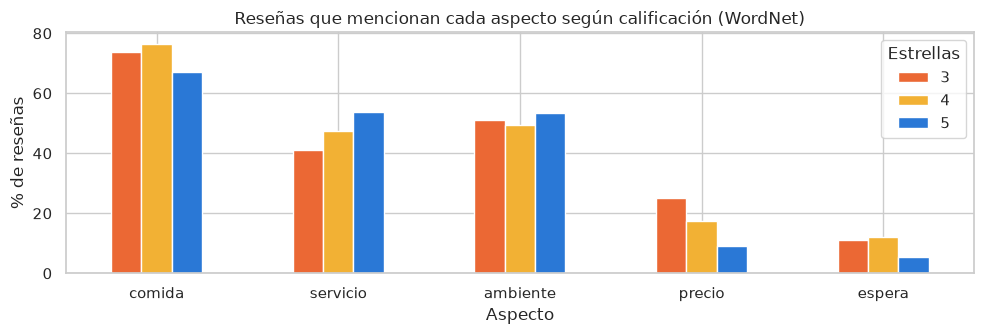

In [33]:
# Sensibilidad: resultado con y sin la revisión manual
asp_sin = pct_aspectos(df, mapa_auto)
cols = ["servicio", "precio", "espera"]
print(pd.concat({"con revisión": asp_cal[cols], "sin revisión": asp_sin[cols]}, axis=1))

asp_cal.T.plot(kind="bar", figsize=(10, 3.5), color=["#eb6834", "#f2b134", "#2a78d6"])
plt.title("Reseñas que mencionan cada aspecto según calificación (WordNet)")
plt.ylabel("% de reseñas")
plt.xlabel("Aspecto")
plt.xticks(rotation=0)
plt.legend(title="Estrellas")
plt.tight_layout()
plt.show()

**Interpretación:**

- WordNet asigna correctamente los sustantivos principales: *comida, platos, sopa, caldo, postres* a comida; *atención, servicio, personal, mozos* a servicio; *lugar, ambiente, vista, terraza* a ambiente; *precio, costo* a precio; *cola, espera, demora* a espera. No clasifica platos peruanos (*ceviche*, *lomo*, *chicha*, *gallina*): no tienen entrada en WordNet o su sentido principal no es el de comida.
- La **precisión estimada por revisión manual** es 75 % (72 de 96 asignaciones). Varía por aspecto: comida 35 de 37 y servicio 9 de 10, pero ambiente solo 21 de 40, porque los synsets de lugar son muy generales.
- Resultado (con revisión):
  - **Servicio** es el único aspecto cuya tasa de mención sube con la calificación: 41.2 % en 3 estrellas, 47.5 % en 4 y 53.9 % en 5.
  - **Precio** baja con la calificación: 25.0 %, 17.6 % y 9.1 %.
  - **Espera** aparece en 11.2 % y 12.2 % de las reseñas de 3 y 4 estrellas, frente a 5.3 % en 5 estrellas.
  - Comida (73.8 / 76.5 / 67.1) y ambiente (51.2 / 49.6 / 53.5) se mencionan en todas las calificaciones sin una tendencia clara.
- **Sensibilidad:** sin la revisión manual, servicio queda en 42.5 / 47.9 / 54.3, precio en 26.2 / 19.7 / 12.5 y espera no cambia. Las cifras varían poco y **las conclusiones se mantienen**: la revisión mejora la exactitud de los conteos, pero no define el resultado.

## 6. Modelos sobre las reseñas

### Técnica 13: TF-IDF por restaurante (`TextCollection.tf_idf`)

TF-IDF pondera cada término por su frecuencia en un documento (TF) y por lo raro que es en la colección (IDF = log(N documentos / documentos que contienen el término)). Un término frecuente en un restaurante y ausente en los demás obtiene un valor alto; un término presente en todos los restaurantes obtiene IDF = 0. `TextCollection` de NLTK calcula ambos factores. Cada restaurante es un documento formado por todas sus reseñas (texto corregido, sin stopwords).

**Caso de uso:** encontrar los términos que distinguen a cada restaurante (platos, características del local), útil para su posicionamiento.

In [34]:
# Se quitan también stopwords en inglés: hay algunas reseñas escritas en inglés
STOP_TFIDF = STOP | STOP_EN
docs = {r: [t for ts in g["tokens_corr"] for t in ts
            if t not in STOP_TFIDF and len(t) > 1]
        for r, g in df.groupby("restaurante")}
coleccion = TextCollection(list(docs.values()))
print(f"Documentos (restaurantes): {len(docs)} | "
      f"tokens en la colección: {len(coleccion):,}")
print("IDF:", {w: round(coleccion.idf(w), 3) for w in ["comida", "atención", "ceviche",
                                                        "sopa", "anticuchos"]})

filas = []
for rest, toks in docs.items():
    frec = FreqDist(toks)
    candidatos = [w for w, f in frec.items() if f >= 3]  # mínimo 3 menciones
    puntajes = sorted(((coleccion.tf_idf(w, toks), w) for w in candidatos),
                      reverse=True)[:6]
    filas.append({"restaurante": rest, "reseñas": (df["restaurante"] == rest).sum(),
                  "términos distintivos (TF-IDF)": ", ".join(w for _, w in puntajes)})
pd.DataFrame(filas).sort_values("reseñas", ascending=False)

Documentos (restaurantes): 13 | tokens en la colección: 14,068
IDF: {'comida': 0.0, 'atención': 0.0, 'ceviche': 0.486, 'sopa': 1.179, 'anticuchos': 1.466}


,restaurante,reseñas,términos distintivos (TF-IDF)
11,Siete Sopas Lince,103,"sopa, sopas, caldo, pan, pancito, campesino"
10,Restaurante La Rosa Náutica,96,"mar, vista, romántica, especiales, rosa, velada"
5,Panchita - Miraflores,95,"panchita, limeña, nivel, miraflores, gallina, abundantes"
4,La Mar Restaurante,93,"ceviches, ceviche, extraordinaria, conchas, pulpo, pescados"
0,Cala Restaurante & Lounge,93,"mar, vista, cala, frente, puesto, vinos"
2,El Rancho de Robertin,90,"chancho, palo, carapulcra, juegos, niños, zoológico"
7,Restaurant Huaca Pucllana,90,"huaca, vista, pucllana, terraza, inca, arqueológico"
6,Punto Azul,89,"azul, mariscos, ceviche, pescado, nikkei, extra"
9,Restaurante Javier,88,"vista, mar, barranco, libre, anticuchos, larga"
1,Caldo De Gallina El Buen Sabor,85,"caldo, gallina, chaufa, cremas, brasa, pollo"


In [35]:
# Verificación de las reseñas de "Tapas San Miguel"
tapas = df[df["restaurante"] == "Tapas San Miguel"]
print("Enlace de origen:", tapas["enlace"].unique()[0])
for t in tapas["texto"].head(3):
    print(" -", textwrap.shorten(sin_simbolos(t), width=85))

# Impacto de conservar estas 25 reseñas en el análisis de aspectos (Técnica 12)
dif = (pct_aspectos(df[df["restaurante"] != "Tapas San Miguel"], mapa_aspecto)
       - asp_cal).abs().max().max()
print(f"\nCambio máximo en el % de reseñas por aspecto si se excluyen: {dif:.1f} puntos")

Enlace de origen: https://cityperu.com/restaurante/san-miguel/restaurant-la-leyenda/
 - Excelente Centro Turístico En Amazonas
 - Podrás disfrutar de la tranquilidad que te ofrece esas aguas cálidas. Disfrutar [...]
 - Muy buen lugar. Exquisitos sudados y chilcanos de peces de agua dulce.

Cambio máximo en el % de reseñas por aspecto si se excluyen: 1.9 puntos


**Interpretación:**

- Los términos con IDF = 0 (*comida*, *atención*) aparecen en los 13 restaurantes y no distinguen a ninguno; *anticuchos* (IDF = 1.466) aparece en pocos.
- TF-IDF recupera la propuesta de cada restaurante sin conocerla de antemano:
  - *Siete Sopas*: sopa, caldo, pan campesino.
  - *Caldo De Gallina El Buen Sabor*: caldo, gallina, chaufa.
  - *La Mar*: ceviches, conchas, pulpo.
  - *El Rancho de Robertin*: chancho al palo, carapulcra, juegos, niños, zoológico (local familiar).
  - *Huancahuasi*: patasca, pachamanca, trucha, show, danzas (comida de la sierra con espectáculo).
  - *Huaca Pucllana*: huaca, terraza, arqueológico.
  - *La Rosa Náutica*: mar, vista, romántica, velada.
- **Hallazgo de calidad de datos:** para *Tapas San Miguel* los términos distintivos son *aventura, leyenda, canopy*. La verificación muestra que el enlace de origen es `/san-miguel/restaurant-la-leyenda/` y que las reseñas hablan de un centro turístico en Amazonas. Estas 25 reseñas no corresponden a un restaurante de tapas en San Miguel; el error viene del portal o de la asociación nombre-enlace durante el scraping.
- **Decisión:** las 25 filas se conservan en todo el análisis porque son texto real extraído y su impacto es pequeño (25 de 1,012 reseñas, 2.5 %). Al excluirlas, el porcentaje de reseñas por aspecto de la Técnica 12 cambia como máximo 1.9 puntos.
- Se agregaron las stopwords en inglés porque una reseña de *Punto Azul* en inglés hacía aparecer *the, was, very* como términos distintivos.

### Técnica 14: Clasificación de sentimiento con Naive Bayes (`NaiveBayesClassifier`)

Naive Bayes estima la probabilidad de cada clase a partir de la presencia de rasgos (features), asumiendo independencia entre ellos. La etiqueta se toma de la calificación que el propio cliente dio en CityPeru: **5 estrellas = "excelente"** y **3-4 estrellas = "no_excelente"** (no hay reseñas de 1 o 2 estrellas). Los rasgos siguen el esquema de bolsa de palabras del libro de NLTK: para las *n* raíces (Técnica 4, sobre el texto corregido de la Técnica 11) más frecuentes del entrenamiento se indica si están o no en la reseña (`contiene(raíz)`: True/False). La raíz `no` se conserva como rasgo.

La partición es estratificada (75 % entrenamiento, 25 % prueba) con semilla fija. Como la clase "excelente" es el 69 % de los datos, se entrena un modelo con todo el entrenamiento y otro con el entrenamiento balanceado, y ambos se comparan contra la línea base de predecir siempre la clase mayoritaria. El tamaño *n* del vocabulario se elige con validación cruzada sobre el entrenamiento balanceado, sin usar el conjunto de prueba, y se reutiliza en el modelo no balanceado.

**Caso de uso:** identificar automáticamente reseñas que no son excelentes (posibles quejas) y conocer qué palabras pesan más en esa decisión.

In [36]:
df["clase"] = np.where(df["calificacion"] == 5, "excelente", "no_excelente")
datos = list(zip(df["stems_corr"], df["clase"], df.index))

# Partición estratificada 75/25 con semilla fija
rng = random.Random(SEMILLA)
train, test = [], []
for clase in ["excelente", "no_excelente"]:
    grupo = [d for d in datos if d[1] == clase]
    rng.shuffle(grupo)
    corte = int(len(grupo) * 0.75)
    train += grupo[:corte]
    test += grupo[corte:]

# Versión balanceada: submuestreo de la clase mayoritaria en entrenamiento
tr_exc = [d for d in train if d[1] == "excelente"]
tr_no = [d for d in train if d[1] == "no_excelente"]
train_bal = rng.sample(tr_exc, len(tr_no)) + tr_no

print(f"Train: {len(train)} {dict(Counter(c for _, c, _ in train))}")
print(f"Train balanceado: {len(train_bal)} {dict(Counter(c for _, c, _ in train_bal))}")
print(f"Test: {len(test)} {dict(Counter(c for _, c, _ in test))}")

Train: 758 {'excelente': 520, 'no_excelente': 238}
Train balanceado: 476 {'excelente': 238, 'no_excelente': 238}
Test: 254 {'excelente': 174, 'no_excelente': 80}


In [37]:
def vocabulario(datos_tr, n):
    # Las n raíces presentes en más reseñas de entrenamiento (empates por orden alfabético)
    fd_doc = FreqDist(s for stems, _, _ in datos_tr for s in set(stems))
    return [s for s, _ in sorted(fd_doc.items(), key=lambda x: (-x[1], x[0]))[:n]]


def rasgos(stems, vocab):
    presentes = set(stems)
    return {f"contiene({s})": (s in presentes) for s in vocab}


def entrenar(datos_tr, n):
    vocab = vocabulario(datos_tr, n)
    modelo = NaiveBayesClassifier.train([(rasgos(st, vocab), c) for st, c, _ in datos_tr])
    return modelo, vocab


def predecir(modelo, vocab, datos_ev):
    return [modelo.classify(rasgos(st, vocab)) for st, _, _ in datos_ev]


def recall_promedio(ref, pred):
    # Promedio del recall de ambas clases (accuracy balanceada)
    return np.mean([np.mean([p == c for r, p in zip(ref, pred) if r == c])
                    for c in set(ref)])


# Elección del tamaño de vocabulario con validación cruzada de 5 particiones
cv = train_bal[:]
random.Random(SEMILLA).shuffle(cv)
filas = []
for n in [50, 100, 200, 300, 500, 1000]:
    puntajes = []
    for k in range(5):
        val = cv[k::5]
        ent = [d for j, d in enumerate(cv) if j % 5 != k]
        modelo, vocab = entrenar(ent, n)
        puntajes.append(recall_promedio([c for _, c, _ in val], predecir(modelo, vocab, val)))
    filas.append({"n_raices": n, "recall_promedio_cv": np.mean(puntajes)})
tabla_cv = pd.DataFrame(filas).round(3)
N_RAICES = int(tabla_cv.loc[tabla_cv["recall_promedio_cv"].idxmax(), "n_raices"])
print("Tamaño de vocabulario elegido:", N_RAICES)
tabla_cv.set_index("n_raices").T.style.format("{:.3f}")

Tamaño de vocabulario elegido: 300


n_raices,50,100,200,300,500,1000
recall_promedio_cv,0.670,0.655,0.690,0.700,0.688,0.679


In [38]:
def evaluar(modelo, vocab, nombre):
    ref = [c for _, c, _ in test]
    pred = predecir(modelo, vocab, test)
    test_feats = [(rasgos(st, vocab), c) for st, c, _ in test]
    fila = {"modelo": nombre, "accuracy": nltk_accuracy(modelo, test_feats),
            "recall_promedio": recall_promedio(ref, pred)}
    ref_s, pred_s = defaultdict(set), defaultdict(set)
    for i, (r, p) in enumerate(zip(ref, pred)):
        ref_s[r].add(i)
        pred_s[p].add(i)
    for c in ["excelente", "no_excelente"]:
        fila[f"precision_{c}"] = precision(ref_s[c], pred_s[c]) or 0
        fila[f"recall_{c}"] = recall(ref_s[c], pred_s[c])
        fila[f"f1_{c}"] = f_measure(ref_s[c], pred_s[c]) or 0
    return fila


nb, vocab_nb = entrenar(train, N_RAICES)
nb_bal, vocab_bal = entrenar(train_bal, N_RAICES)

base = Counter(c for _, c, _ in test)["excelente"] / len(test)
resultados = pd.DataFrame([evaluar(nb, vocab_nb, "NB"),
                           evaluar(nb_bal, vocab_bal, "NB balanceado")])
resultados.loc[len(resultados)] = {"modelo": "Base (siempre 'excelente')", "accuracy": base,
                                   "recall_promedio": 0.5,
                                   "precision_excelente": base, "recall_excelente": 1.0,
                                   "f1_excelente": 2 * base / (1 + base),
                                   "precision_no_excelente": 0.0, "recall_no_excelente": 0.0,
                                   "f1_no_excelente": 0.0}
margen = 1.96 * np.sqrt(base * (1 - base) / len(test))
print(f"Margen de error aproximado de la accuracy (95 %, n={len(test)}): ±{margen:.1%}")
resultados.set_index("modelo").round(3).T

Margen de error aproximado de la accuracy (95 %, n=254): ±5.7%


modelo,NB,NB balanceado,Base (siempre 'excelente')
accuracy,0.701,0.720,0.685
recall_promedio,0.620,0.681,0.500
precision_excelente,0.753,0.801,0.685
recall_excelente,0.839,0.787,1.000
f1_excelente,0.793,0.794,0.813
precision_no_excelente,0.533,0.554,0.000
recall_no_excelente,0.400,0.575,0.000
f1_no_excelente,0.457,0.564,0.000


In [39]:
# Matrices de confusión de NLTK presentadas como tabla
ETIQ = ["excelente", "no_excelente"]


def matriz(modelo, vocab):
    cm = ConfusionMatrix([c for _, c, _ in test], predecir(modelo, vocab, test))
    return pd.DataFrame([[cm[r, p] for p in ETIQ] for r in ETIQ],
                        index=[f"real: {e}" for e in ETIQ],
                        columns=[f"pred: {e}" for e in ETIQ])


print(pd.concat({"NB": matriz(nb, vocab_nb), "NB balanceado": matriz(nb_bal, vocab_bal)},
                axis=1).to_string())
print()
nb_bal.show_most_informative_features(15)

                                NB                      NB balanceado                   
                   pred: excelente pred: no_excelente pred: excelente pred: no_excelente
real: excelente                146                 28             137                 37
real: no_excelente              48                 32              34                 46

Most Informative Features
           contiene(car) = True           no_exc : excele =      7.7 : 1.0
        contiene(pequeñ) = True           no_exc : excele =      7.7 : 1.0
           contiene(bañ) = True           no_exc : excele =      7.0 : 1.0
           contiene(dan) = True           no_exc : excele =      6.3 : 1.0
          contiene(sirv) = True           no_exc : excele =      6.3 : 1.0
          contiene(casi) = True           no_exc : excele =      5.7 : 1.0
           contiene(pag) = True           no_exc : excele =      5.7 : 1.0
           contiene(pes) = True           no_exc : excele =      5.7 : 1.0
         contiene

In [40]:
# Ejemplos del modelo balanceado: el acierto y el error con mayor P(no_excelente)
probs = [(nb_bal.prob_classify(rasgos(st, vocab_bal)).prob("no_excelente"), c, i)
         for st, c, i in test]
for clase_real, etiqueta in [("no_excelente", "acierto"), ("excelente", "error")]:
    p, _, i = max(x for x in probs if x[1] == clase_real)
    fila = df.loc[i]
    print(f"[{etiqueta}] P(no_excelente)={p:.2f} | real: {fila['calificacion']} estrellas | "
          f"{fila['restaurante']}")
    print(textwrap.fill(sin_simbolos(fila["texto"])[:300], width=88, initial_indent="   ",
                        subsequent_indent="   "))

[acierto] P(no_excelente)=1.00 | real: 3 estrellas | El Rancho de Robertin
   Su especialidad es el chancho al palo. Normalmente hay mucha gente en este lugar, por
   tener la fama de ser muy bueno. Sin embargo, no tuve la mejor experiencia, ya que si
   vas en feriado, fiestas patrias, o alguna ocasión en la que haya asueto, tendrás que
   hacer cola para ingresar; el lugar estaba re
[error] P(no_excelente)=1.00 | real: 5 estrellas | Restaurante Huancahuasi Javier Prado
   Fuimos con mi familia a eso de las 12:30 - 12:45 pm, y tuvimos que esperar casi 45
   minutos para entrar, ya que no hicimos reserva. Sin embargo cuando entramos la
   atención fue super rápida, esperamos a lo sumo 10 minutos o menos para que nos
   entreguen la comida que pedimos, todo estaba super rico, lo


**Interpretación:**

- La validación cruzada eligió un vocabulario de 300 raíces (recall promedio de 0.70 en validación).
- En el conjunto de prueba, la línea base que siempre predice "excelente" acierta 68.5 % de las veces, pero no detecta ninguna reseña "no_excelente" (recall promedio 0.50). Naive Bayes llega a 70.1 % y la versión balanceada a 72.0 %. **La mejora en accuracy (+3.5 puntos) está dentro del margen de error de ±5.7 puntos** que corresponde a 254 reseñas de prueba, por lo que no es concluyente.
- La métrica más informativa es el recall promedio (accuracy balanceada): 0.620 sin balancear y **0.681 con balanceo**, frente a 0.50 de la línea base. El modelo balanceado detecta 46 de las 80 reseñas "no_excelente" (recall 0.575) frente a 32 del modelo sin balancear (0.400), a cambio de clasificar como "no_excelente" 37 reseñas excelentes. Su precisión en esa clase es 0.554: casi la mitad de las alertas son falsas.
- Rasgos más informativos para "no_excelente": `car` (*caro, caros, cara*), `pequeñ` (*pequeño/a*), `bañ` (*baños*), `sirv` (*sirven*), `pag` (*pagar, pago*), `pes` (sobre todo el concesivo *a pesar de*: *pesar* aparece 10 de 13 veces, en línea con *sin embargo* de la Técnica 6), `acept` (*aceptable*) y `porcion`. Coinciden con las Técnicas 6 y 12: precio, porción y servicios del local.
- Limitaciones: el corpus es pequeño (758 reseñas de entrenamiento), las reseñas de 4 estrellas usan casi el mismo vocabulario positivo que las de 5, y Naive Bayes asume independencia entre palabras. El ejemplo de error es una reseña de 5 estrellas que describe una espera de 45 minutos: el modelo la marca como no excelente por su vocabulario. El clasificador sirve para priorizar reseñas a revisar, no para reemplazar la calificación.

## 7. Conclusiones

Se aplicaron 14 técnicas de NLTK sobre las 1,012 reseñas de restaurantes obtenidas por web scraping de CityPeru en la semana 03.

| N | Técnica | Hallazgo principal |
|---|---------|--------------------|
| 1 | Segmentación de oraciones | El 46.8 % de las reseñas tiene una sola oración; 4 de las 5 reseñas más detalladas son de 4 estrellas. |
| 2 | Tokenización | Las reseñas de 3 estrellas tienen 43.4 tokens en promedio frente a 27.2 en 5 estrellas (60 % más largas). |
| 3 | Stopwords | El 46 % de las palabras son stopwords; quitarlas deja 14,404 tokens con contenido. |
| 4 | Stemming | Reduce el vocabulario 35.6 %, pero divide *recomiendo/recomendable* y mezcla *comida/comer*. |
| 5 | FreqDist | Los temas principales son comida (469), atención (374) y lugar (330); 58 % del vocabulario son hapax. |
| 6 | ConditionalFreqDist | En 3 estrellas *no* es 4.2 veces más frecuente que en 5; *precio*, *porción*, *mal* y *normal* caracterizan las reseñas de menor nota. 21 de 37 reseñas que mencionan la cola son de Siete Sopas, la mayoría de 5 estrellas. |
| 7 | N-gramas y colocaciones | Detecta platos sin lista previa: lomo saltado, caldo de gallina, chancho al palo, chicha morada, chicha de jora, pisco sour. |
| 8 | Concordancia | Las quejas de precio se refieren a la relación precio-porción; *precio* destaca solo en 3 estrellas, mientras *atención* y *vista* crecen con la calificación. |
| 9 | POS tagging | Etiquetador entrenado con 92.7 % de exactitud en `cess_esp`; *normal* es típico de 3 estrellas y *deliciosa/espectacular* de 5. |
| 10 | Chunking | 1,714 pares aspecto-opinión; los precios se describen como *razonables* y *accesibles*, y en 3 estrellas aparecen *experiencia mala* y *platos elementales*. |
| 11 | Distancia de edición | 49 correcciones aplicadas (*atencion*, *exelente*, *tambien*) y unificación de la variante *cebiche*; *atención* pasa de 374 a 401 menciones. |
| 12 | WordNet | Servicio es el único aspecto que sube con la calificación (41.2 % -> 53.9 %); precio baja (25.0 % -> 9.1 %). Precisión estimada por revisión manual de 75 %; sin revisión las conclusiones se mantienen. |
| 13 | TF-IDF | Identifica la propuesta de cada restaurante y revela que las reseñas de *Tapas San Miguel* corresponden a otro lugar (centro turístico en Amazonas). |
| 14 | Naive Bayes | Recall promedio de 0.681 frente a 0.50 de la línea base; la mejora en accuracy (72.0 % frente a 68.5 %) está dentro del margen de error. |

**Conclusiones para el negocio:**

- El **servicio** es el único aspecto cuya mención aumenta con la calificación (41.2 % de las reseñas de 3 estrellas, 47.5 % de 4 y 53.9 % de 5), y el par aspecto-opinión más frecuente es *atención buena*. Una buena atención acompaña a la nota máxima.
- El **precio** (en relación con la porción) y la **espera** son los aspectos que más aparecen en las reseñas que no dan la nota máxima. La cola de *Siete Sopas Lince* no afecta mucho la nota: de sus 21 reseñas que mencionan la cola, 14 son de 5 estrellas.
- Las técnicas de NLTK permiten extraer automáticamente platos, aspectos y opiniones, aunque varias (stemming, chunking, corrección ortográfica y WordNet) requieren revisión humana para descartar errores. En el caso de WordNet se comprobó que esa revisión no cambia las conclusiones.

**Limitaciones de la data:** no hay reseñas de 1 o 2 estrellas, el corpus es pequeño (unas 27,000 palabras) e *Isolina* tiene solo 9 reseñas. Las 25 reseñas de *Tapas San Miguel* no corresponden a ese restaurante; se conservaron porque su impacto es pequeño (2.5 % de las reseñas; el análisis de aspectos cambia como máximo 1.9 puntos sin ellas). Para un análisis más sólido se recomienda volver a ejecutar el scraping verificando la correspondencia nombre-enlace y ampliando el número de reseñas.